# Paper figures — what forgetting looks like *inside* the model

This notebook selects and reproduces the figures worth putting in the paper from the two
internals notebooks:

- `forgetting_internal_features.ipynb` — output scalars, the logit lens, and the top-128
  active-neuron dump (§§1–21);
- `hidden_states_forgetting.ipynb` — the raw residual stream at two token positions (§§1–19).

**Everything already carried by `frequency_and_forgetting.ipynb` is deliberately excluded**
— the count-vs-hazard reversal, the hazard against `num_shared_chunks` / `total_subj_chunks`,
the confidence-stratified and strict-top-1 robustness panels. Those are that notebook's
figures and they are not repeated here.

### The three body figures

| # | Figure | Claim it carries | Source |
|---|---|---|---|
| **1** | Logit-lens depth profile of survive vs. forget-next | Forgetting is a **mid-stack** failure, not a read-out failure: the gap opens at boundary 8 and holds a 0.81–0.90 log-unit plateau from boundary 10 to the final layer | internal §8 |
| **2** | Neuron churn before the flip + predictive AUC | The instability **precedes** the loss and adds to what the output already says: within checkpoints, neurons + internal scalar features reach 0.713 against 0.694 for the scalar features alone | internal §14a, §16 |
| **3** | Probe-vs-output at the flip, and the two regimes of a flip | The representation gap is open **before** the flip (probe 0.44 vs 0.72) and the flip itself removes nothing (DiD +0.076, CI [+0.047, +0.105]); 44% of flips sharpen rather than flatten, and 50% reverse within one checkpoint | hidden §12, internal §9 |

Those three answer *where*, *when*, and *what kind of event* — which is the minimum a
mechanistic story about forgetting has to answer.

### The five appendix figures

| # | Figure | Why it belongs in the appendix | Source |
|---|---|---|---|
| **A1** | Layer geography of a fact's neurons | Describes the band used in Figs. 1–2: layers 8–13 are where a fact's neurons are least shared. Sparsity and volatility peak elsewhere | internal §13 |
| **A2** | Cross-validation audit of the residual-stream probe | A methodological correction that **overturns a published-in-draft claim** (AUC 0.476 → 0.750 under the strict measure); anyone reusing these features needs it | hidden §8 |
| **A3** | Cross-fitted separability + leave-one-relation-out transfer | The main caveat on every probe number: the "knows-it" direction is largely **lexical/relation identity** (LORO 0.57 vs 0.69 matched) | hidden §9, §10 |
| **A4** | Neuron-mates share a fate | The negative control on interference: shared mid-stack neurons produce **synchrony, never competition** — and *anti*-competition in all four cells of the 2×2 | internal §20 |
| **A5** | Noise-floor null | Rules out the deflationary reading of the whole project (real correctness is 2.2× more persistent than a calibrated stochastic read-out) | internal §10 |

A1 and A5 are load-bearing for the body but too preliminary to spend a body slot on; A2 and A3
are the honesty section; A4 is the one strong null.

> **Numbers reproduce, panels are re-laid-out.** Every statistic below is recomputed from the
> artefacts, not copied. Where a source figure had panels that only served the exploratory
> narrative, they are dropped so each figure makes exactly one point.

In [54]:
# ── shared setup ──────────────────────────────────────────────────────────────────────
import glob, re, json, os, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from matplotlib.patches import Patch
from scipy.stats import spearmanr, rankdata, mannwhitneyu

# visual style, shared with the three source notebooks
INK, INK2, GRID, SURF = "#0b0b0b", "#52514e", "#e6e5e1", "#fcfcfb"
BLUE, ORANGE, PURPLE, NEUTRAL = "#2a78d6", "#eb6834", "#7b5ea7", "#f0efec"
# BLUE/ORANGE is the validated pair (OKLab dE 33.6 normal, 24.7 CVD); PURPLE is the third
# hue that survives both checks.  RED is never paired with ORANGE (dE 3.6 under deuteranopia).
plt.rcParams.update({
    "figure.dpi": 130,
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "text.color": INK, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "xtick.color": INK2, "ytick.color": INK2, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "axes.edgecolor": GRID, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 10, "axes.titlesize": 11, "legend.frameon": False,
})
PCT = FuncFormatter(lambda v, _: f"{v:.0%}")

def clean(ax, axis="y"):
    """Recessive axes: one grid direction, no spines, no ticks."""
    ax.set_axisbelow(True)
    ax.grid(axis=axis, alpha=.4)
    ax.tick_params(length=0)
    for s in ax.spines.values():
        s.set_visible(False)

def auc1(score, y):
    """P(score ranks a positive above a negative).  NaN-safe."""
    m = np.isfinite(score)
    score, y = score[m], np.asarray(y)[m].astype(bool)
    r = rankdata(score)
    n1, n0 = y.sum(), (~y).sum()
    return (r[y].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)

features:
gold_prob (float, 0–1) — length-normalized probability of the whole gold answer: exp(mean per-token logprob) over all gold_ntokens tokens (internal.py:322-327).

gold_rank (int, 0-based) — how many vocabulary tokens outrank the gold token; 0 = top-1

pred_entropy (float, nats) — Shannon entropy of the full next-token distribution at the answer position. A property of the model's uncertainty, not of the gold answer — it's the one feature that never looks at the label.

In [55]:
# ── the fact x checkpoint panel (the `--no-hidden` internal run) ──────────────────────
TRAJ_DIR = "data/artifacts/recall/rotemab_15shot_top10_internal"
files = sorted(glob.glob(f"{TRAJ_DIR}/*.parquet"),
               key=lambda f: int(re.search(r"step(\d+)", f).group(1)))
steps = [int(re.search(r"step(\d+)", f).group(1)) for f in files]
FEATURES = ["correct", "is_top1", "gold_prob", "answer_margin", "gold_rank",
            "pred_entropy", "resolution_depth"]

# `excluded` (the answer leaks into the few-shot prompt) is a property of the *fact*, so the
# surviving set is identical at every checkpoint and the panel stays balanced.
frames = []
for f, s in zip(files, steps):
    d = pd.read_parquet(f)
    d = d[~d["excluded"]].copy()
    d["step"] = s
    frames.append(d[["id", "step"] + FEATURES])
long = pd.concat(frames, ignore_index=True)

P = {c: long.pivot(index="id", columns="step", values=c).reindex(columns=steps)
     for c in FEATURES}
ids = P["correct"].index
correct = P["correct"].to_numpy().astype(bool)          # (n_facts, 13)
n_facts, n_steps = correct.shape

props = pd.read_csv("15_shot_top_10_trajectory_with_fact_properites.csv").set_index("id").reindex(ids)
prop = props["prop"].to_numpy()
exposure = props["num_shared_chunks"].to_numpy()

# Transition panels over currently-correct (fact, checkpoint) observations.
#   *F = fact row, *T = checkpoint index t (fact correct at t), *FG = wrong at t+1 (the target).
#   Parallel arrays, one per observation: P[feat].to_numpy()[XF, XT] reads that feature at the
#   still-correct checkpoint.  A fact recurs once per checkpoint it survives, hence GroupKFold.
#   X* : every transition           -- for anything measured AT or ACROSS the flip
#   A* : only t >= 1                -- so a *backward* churn cos(t-1, t) exists, i.e. the
#                                      strictly ante-hoc panel Fig. 2b is scored on
def _transitions(t0):
    f, t, y = [], [], []
    for i in range(t0, n_steps - 1):
        j = np.where(correct[:, i])[0]
        f.append(j); t.append(np.full(j.size, i)); y.append(~correct[j, i + 1])
    return np.concatenate(f), np.concatenate(t), np.concatenate(y).astype(bool)

XF, XT, XFG = _transitions(0)
AF, AT, AFG = _transitions(1)

print(f"{n_facts} scoreable facts x {n_steps} checkpoints ({steps[0]//1000}k -> {steps[-1]//1000}k)")
print(f"accuracy {correct[:, 0].mean():.1%} -> {correct[:, -1].mean():.1%}")
print(f"transitions: {XFG.size} total ({XFG.mean():.1%} forgotten next), "
      f"{AFG.size} ante-hoc ({AFG.mean():.1%})")

1310 scoreable facts x 13 checkpoints (50k -> 658k)
accuracy 14.4% -> 41.5%
transitions: 4154 total (24.1% forgotten next), 3965 ante-hoc (23.7%)


In [56]:
# ── the columns the FEATURES panel did not keep: per-layer logit-lens ranks, top1_prob ──
EXTRA = ["top1_prob", "pred_entropy", "gold_prob"]
_frames = []
for f in files:
    d = pd.read_parquet(f)
    _frames.append(d[~d["excluded"]].set_index("id").reindex(ids))
NEWP = {c: np.column_stack([fr[c].to_numpy() for fr in _frames]) for c in EXTRA}
#GRL is gold rank by layer, shape (n_facts, n_steps, n_boundaries)
GRL = np.stack([np.stack(fr["gold_rank_by_layer"].to_numpy()).astype(float)
                for fr in _frames], axis=1)          
n_bound = GRL.shape[2]

# Fix the final logit-lens boundary: the last `output_hidden_states` entry is
# already post-final-norm, but the extractor mistakenly applied the final norm
# again before the LM head. This produced ranks from a doubly-normalized state.
# Since this boundary should exactly match the model's true output distribution,
# replace it with the rank computed directly from the final logits (`gold_rank`).
# Earlier boundaries are genuinely pre-norm and therefore remain unchanged.
_true18 = np.column_stack([fr["gold_rank"].to_numpy().astype(float) for fr in _frames])
_agree = (GRL[:, :, n_bound - 1] == _true18).mean()
GRL[:, :, n_bound - 1] = _true18
print(f"gold_rank_by_layer -> {GRL.shape}  ({n_bound} layer boundaries: 0 = embeddings)")
print(f"boundary {n_bound-1} repaired from the true final-layer `gold_rank` "
      f"(the stored lens value agreed with it on only {_agree:.1%} of cells)")

gold_rank_by_layer -> (1310, 13, 19)  (19 layer boundaries: 0 = embeddings)
boundary 18 repaired from the true final-layer `gold_rank` (the stored lens value agreed with it on only 2.6% of cells)


---
# Figure 1 (body) — forgetting is a mid-stack failure

**Source:** `forgetting_internal_features.ipynb` §8.
**Papers:** nostalgebraist (2020), *the logit lens*; Belrose et al. (2023), *Tuned Lens*;
Lad et al. (2024), *Stages of Inference*; Geva et al. (2023), *Dissecting Recall of Factual
Associations*.

`gold_rank_by_layer` gives the rank of the gold token under the logit lens at **every** layer
boundary, so the same comparison can be run through depth. That is what turns a tautology into
a localisation: the two groups are not different everywhere, they are different in one band.

Every (fact, checkpoint) at which the fact is **correct** contributes one row, labelled by
whether it survives to the next checkpoint. **Fig. 1a**: the median $\log_{10}$ gold rank at
each boundary, per group — lower is better, 0 means the gold token is rank 1. **Fig. 1b**: the
gap between the groups, with a 95% interval bootstrapped **over facts** (a fact's transitions are
not independent observations, so resampling transitions would understate the interval).


*Caveat this figure shares with every other one here:* `correct` is scored on the **15-shot**
prompt, while the lens — like every internal quantity in this notebook — is measured on the
**zero-shot** cloze, so that the answer position is unconditioned and comparable across shot
counts. Among facts scored correct, only 39.8% have the gold token as the zero-shot argmax. The
event and the measurement therefore live on two different prompts; the depth profile is a
statement about how the fact is *stored*, not about the decode that scored it.

### Fig. 1a — both groups climb together, then split mid-stack

*A fact about to be forgotten fails where the attribute is extracted, and never recovers.*

Checkpoint-balanced median logit-lens rank of the gold token at each layer boundary, for
currently-correct facts that survive to the next checkpoint (blue) against those forgotten at it
(orange). Lower is better; 0 means the gold token is rank 1. Shading marks the mid-stack band
(boundaries 8–13).


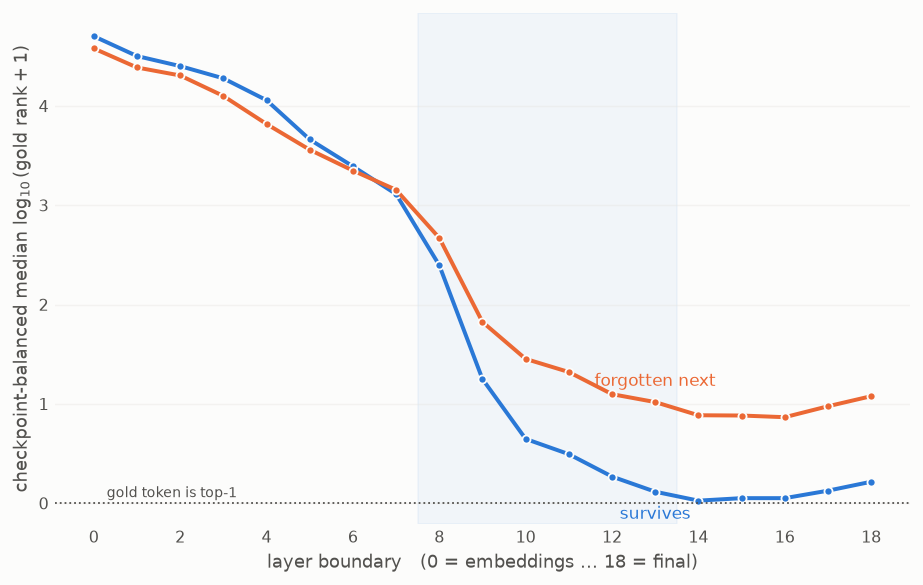

4154 transitions, forget rate 24.1%
median gold rank (back on the rank scale, 0 = top-1):
  survives : 50269.7 31747.7 25148.1 18935.3 11407.6 4589.3 2461.2 1292.2  247.8   16.8    3.4    2.1    0.9    0.3    0.1    0.1    0.1    0.3    0.6
  forgotten: 37884.4 24350.4 20237.7 12590.4 6570.1 3617.4 2230.6 1427.3  467.7   65.7   27.3   19.9   11.5    9.4    6.7    6.6    6.3    8.4   10.9


In [57]:
# ── Fig. 1a — checkpoint-balanced logit-lens depth profile  (internal §8) ────────────
# log10(rank + 1),  `gold_rank` is 0-BASED 
log_rank = np.log10(GRL + 1.0)
cur = log_rank[XF, XT]                                   # (n_transitions, n_boundaries)

def _balanced(C, T, Y):
    """Equal-weight mean of the checkpoint-specific group medians.
    Pooling all transitions would let earlier checkpoints rule forgotten while later checkpoints rule the survivors.  
    Computing the two medians INSIDE each checkpoint and then averaging gives every checkpoint equal say.
    """
    ms, mf = [], []
    for t in np.unique(T):
        m = T == t
        if (m & ~Y).any() and (m & Y).any():
            ms.append(np.nanmedian(C[m & ~Y], axis=0))
            mf.append(np.nanmedian(C[m & Y], axis=0))
    return np.nanmean(ms, axis=0), np.nanmean(mf, axis=0)

med_s, med_f = _balanced(cur, XT, XFG)
gap = med_f - med_s

# Cluster bootstrap over facts: a resampled fact contributes its whole block of transitions.
rng = np.random.default_rng(0)
uf = np.unique(XF)
# pos: fact -> all transition rows belonging to that fact
pos = {f: np.where(XF == f)[0] for f in uf}
boot = np.full((500, n_bound), np.nan)
for b in range(len(boot)):
    sel = np.concatenate([pos[f] for f in rng.choice(uf, uf.size, replace=True)])
    bs, bf = _balanced(cur[sel], XT[sel], XFG[sel])
    boot[b] = bf - bs
lo_b, hi_b = np.nanpercentile(boot, [2.5, 97.5], axis=0)

xl = np.arange(n_bound)
fig, ax1 = plt.subplots(figsize=(7.2, 4.6))
ax1.axvspan(7.5, 13.5, color=BLUE, alpha=.05, zorder=0)
ax1.plot(xl, med_s, color=BLUE, lw=2.2, marker="o", ms=4.5, mec=SURF, mew=1)
ax1.plot(xl, med_f, color=ORANGE, lw=2.2, marker="o", ms=4.5, mec=SURF, mew=1)
ax1.annotate("survives", (xl[13], med_s[13]), color=BLUE, fontsize=9.5,
             xytext=(0, -15), textcoords="offset points", ha="center")
ax1.annotate("forgotten next", (xl[13], med_f[13]), color=ORANGE, fontsize=9.5,
             xytext=(0, 9), textcoords="offset points", ha="center")
ax1.axhline(0, color=INK2, lw=1, ls=":")
ax1.text(0.3, 0.06, "gold token is top-1", fontsize=8, color=INK2)
ax1.set_xlabel("layer boundary   (0 = embeddings … 18 = final)")
ax1.set_ylabel(r"checkpoint-balanced median $\log_{10}(\mathrm{gold\ rank}+1)$")
ax1.set_xticks(xl[::2])
clean(ax1)
fig.tight_layout(); plt.show()

print(f"{XFG.size} transitions, forget rate {XFG.mean():.1%}")
print("median gold rank (back on the rank scale, 0 = top-1):")
print("  survives :", " ".join(f"{10**v - 1:6.1f}" for v in med_s))
print("  forgotten:", " ".join(f"{10**v - 1:6.1f}" for v in med_f))


### Fig. 1b — a mid-stack onset, then a sustained gap

*The gap between the two groups, with a 95% interval from a cluster bootstrap over facts — a
fact's transitions are not independent observations, so resampling transitions rather than facts
would understate the interval.*


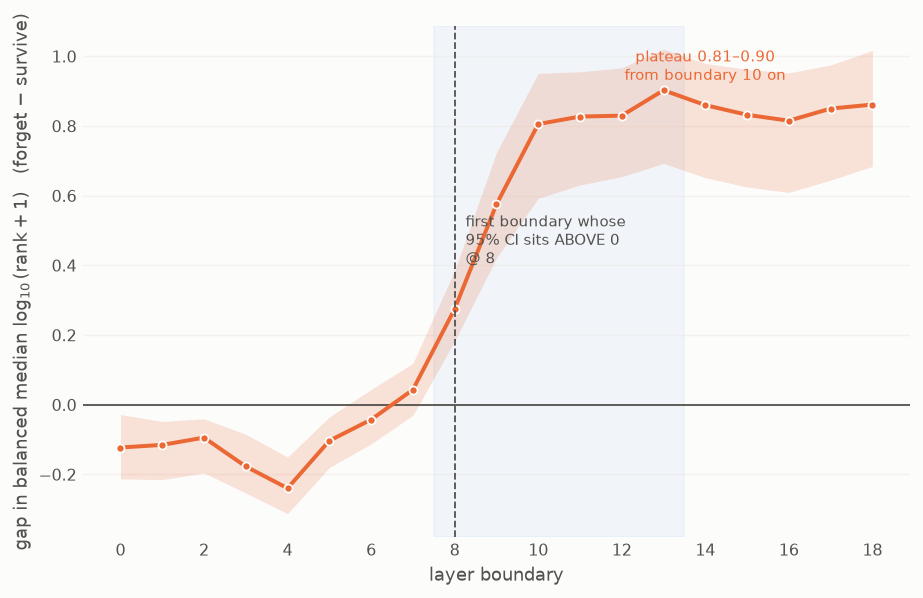

boundary:     0     1     2     3     4     5     6     7     8     9    10    11    12    13    14    15    16    17    18
gap     : -0.12 -0.12 -0.09 -0.18 -0.24 -0.10 -0.04  0.04  0.27  0.57  0.81  0.83  0.83  0.90  0.86  0.83  0.82  0.85  0.86
CI lo   : -0.21 -0.22 -0.20 -0.25 -0.31 -0.18 -0.11 -0.03  0.18  0.42  0.59  0.63  0.65  0.69  0.65  0.62  0.61  0.64  0.68

first boundary whose 95% CI clears zero: 8
largest gap: boundary 13 (0.90); boundaries 10-18 span 0.81-0.90, so this is a plateau, not a peak


In [58]:
# ── Fig. 1b — the gap between the groups, 95% cluster CI over facts  (internal §8) ────
fig, ax2 = plt.subplots(figsize=(7.2, 4.6))
ax2.axvspan(7.5, 13.5, color=BLUE, alpha=.05, zorder=0)
ax2.axhline(0, color=INK2, lw=1)
ax2.fill_between(xl, lo_b, hi_b, color=ORANGE, alpha=.18, linewidth=0)
ax2.plot(xl, gap, color=ORANGE, lw=2.2, marker="o", ms=4.5, mec=SURF, mew=1)
peak = int(np.nanargmax(gap))
sig = np.where(lo_b > 0)[0]
first_sig = int(sig[0]) if len(sig) else None
if first_sig is not None:
    ax2.axvline(first_sig, color=INK2, ls="--", lw=1)
    ax2.annotate(f"first boundary whose\n95% CI sits ABOVE 0\n@ {first_sig}",  # 0-5 clear it below
                 (first_sig, gap[peak] * .45), xytext=(6, 0), textcoords="offset points",
                 fontsize=8.5, color=INK2)
# The gap is a PLATEAU from ~10 on, not a spike; annotate the range rather than a single peak.
ax2.annotate(f"plateau {gap[10:].min():.2f}–{gap[10:].max():.2f}\nfrom boundary 10 on",
             (14, gap[14]), color=ORANGE, fontsize=8.5, ha="center",
             xytext=(0, 14), textcoords="offset points")
ax2.set_xlabel("layer boundary")
ax2.set_ylabel(r"gap in balanced median $\log_{10}(\mathrm{rank}+1)$   (forget − survive)")
ax2.set_xticks(xl[::2])
clean(ax2)
fig.tight_layout(); plt.show()

print("boundary:", " ".join(f"{i:5d}" for i in xl))
print("gap     :", " ".join(f"{v:5.2f}" for v in gap))
print("CI lo   :", " ".join(f"{v:5.2f}" for v in lo_b))
print(f"\nfirst boundary whose 95% CI clears zero: {first_sig}")
print(f"largest gap: boundary {peak} ({gap[peak]:.2f}); boundaries 10-18 span "
      f"{gap[10:].min():.2f}-{gap[10:].max():.2f}, so this is a plateau, not a peak")


**Result.** Through boundaries 0–7 the two groups are not separated in the direction the thesis
needs. If anything the soon-to-be-forgotten facts are *ahead*: at boundaries 0–5 the gap is
**negative with its whole 95% interval below zero** (−0.24 [−0.31, −0.15] at its most extreme,
boundary 4), and boundaries 6–7 straddle zero. **Boundary 8 is the first boundary whose interval
sits entirely above zero** — the first at which the doomed facts are measurably *worse* — which is
the onset the figure is about. From boundary 10 the gap is a **plateau**,
0.81–0.90 log-units, largest at boundary 13 (0.90) and still 0.86 at the final layer. On the rank
scale the median surviving fact reaches gold rank ≈0.9 by boundary 12 and ≈0.1 through 14–16 —
genuinely top-1 — while the median soon-to-be-forgotten fact never gets below ≈6 anywhere in the
stack and ends at ≈11.

This is the shape Geva et al. (2023) predict if the failure is in **attribute extraction** rather
than in the read-out: early-layer processing of the prompt is intact, and the fact is lost where
the attribute should be pulled from the subject representation into the answer position. Because
the gap never closes, it is also not a read-out failure — the deficit is carried all the way to
the logits.

**What this figure no longer claims.** An earlier version reported a sharp peak at boundary 12,
and that peak does not survive. Three separate corrections each flatten it: the median near a mass
point is quasi-discontinuous exactly where the survivors' top-1 share crosses 50%; pooling
transitions let checkpoint mixture (forgotten rows come from earlier checkpoints, mean index 5.4
vs 6.6) masquerade as depth structure; and clipping a 0-based rank at 1 made the floor two ranks
wide. With `log10(rank + 1)`, checkpoint-balanced medians and a fact-cluster bootstrap, what
remains is an **onset** at boundary 8 and a sustained plateau — which is the claim the paper should
make. The onset is the localisation; there is no single peak layer to name.

*Suggested caption.* "(a) Checkpoint-balanced median logit-lens rank of the gold token by layer, for
currently-correct facts that survive to the next checkpoint (blue) vs. those forgotten at it
(orange), over 4 154 transitions. Medians are computed within each checkpoint and averaged, so the
differing checkpoint composition of the two groups cannot produce the effect. (b) Their
difference, with a 95% interval from a cluster bootstrap over facts. The groups are
indistinguishable through boundary 7, separate from boundary 8, and remain separated to the final
layer. Shading marks the mid-stack band (layers 8–13); Fig. A1 shows it is where a fact's neurons
are least shared."


In [59]:
# ── the top-k active-neuron dump: per-(fact, checkpoint, layer) summaries  (internal §13) ──
# Needed by Fig. 2 and by A1/A4.  One streaming pass over the 13 checkpoints x 2 positions.
NEU_DIR = Path("data/artifacts/expermints/15shot_trajectory_top10_internal_with_neurons")
_meta = json.loads((NEU_DIR / f"internal/neurons_step{steps[-1]}_meta.json").read_text())
K_NEU, n_mlp, MISSING = _meta["k"], _meta["n_layers"], _meta["missing_sentinel"]
N_INTER = 5632                      # LMEnt-1B intermediate_size
MID = slice(8, 14)                  # the mid-stack band Fig. 1 localised the failure to.

xlayer = np.arange(n_mlp)

_nids = np.load(NEU_DIR / f"internal/neurons_step{steps[-1]}_ids.npy", allow_pickle=True)
NROW = pd.Index(_nids).get_indexer(ids)                 # dump row -> panel row
assert (NROW >= 0).all(), "the neuron run does not cover every fact in the panel"

def _load(step, pos, what):
    a = np.load(NEU_DIR / f"internal/neurons_step{step}_{pos}_{what}.npy", mmap_mode="r")
    return np.asarray(a[NROW])

def _pair(iA, vA, iB, vB, k):
    """|A n B| and the cosine of two sparse activation vectors over the top-k support, for
    every (fact, layer) at once.  Concatenating the two index sets and sorting puts a shared
    neuron's two copies side by side, so one pass gives both quantities -- no k x k comparison
    and no dense 5632-wide buffer."""
    A, B = iA[..., :k].astype(np.int32), iB[..., :k].astype(np.int32)
    cat = np.concatenate([A, B], -1)
    order = np.argsort(cat, axis=-1, kind="stable")
    s = np.take_along_axis(cat, order, -1)
    eq = s[..., 1:] == s[..., :-1]        # top-k indices are distinct within a set, so an
    vs = np.take_along_axis(              # adjacent equal pair == a shared neuron
        np.concatenate([vA[..., :k], vB[..., :k]], -1), order, -1)
    dot = (vs[..., 1:] * vs[..., :-1] * eq).sum(-1)
    nrm = np.sqrt((vA[..., :k] ** 2).sum(-1) * (vB[..., :k] ** 2).sum(-1))
    return eq.sum(-1), dot / np.maximum(nrm, 1e-12)

def neuron_summaries(pos):
    """(n_facts, n_steps[-lag], n_mlp) float32 summaries.

    State at a checkpoint      H   normalised entropy of the top-k |activation|s
                               PR  participation ratio -- the effective neuron count
                               L1  total top-k activation mass
                               GEN genericity: the mean share of *other panel facts* that
                                   also have this fact's top-k neurons in theirs
    Change between checkpoints COS cosine of the sparse activation vectors, t -> t+1
                               J32 Jaccard of the top-32 index sets,        t -> t+1
    """
    n = len(ids)
    o = {k: np.full((n, n_steps, n_mlp), np.nan, np.float32) for k in ("H", "PR", "L1", "GEN")}
    o.update({k: np.full((n, n_steps - 1, n_mlp), np.nan, np.float32) for k in ("COS", "J32")})
    prev = None
    for t, s in enumerate(steps):
        I, V = _load(s, pos, "idx"), _load(s, pos, "val").astype(np.float32)
        assert (I != MISSING).all(), f"step {s} {pos}: position not located for some fact"
        a = np.abs(V); tot = a.sum(-1)
        p = a / np.maximum(tot, 1e-12)[..., None]
        o["H"][:, t] = -(p * np.log(np.maximum(p, 1e-12))).sum(-1) / np.log(K_NEU)
        o["PR"][:, t] = tot ** 2 / np.maximum((V ** 2).sum(-1), 1e-12)
        o["L1"][:, t] = tot
        for l in range(n_mlp):                     # population share of each top-k neuron
            popc = np.bincount(I[:, l, :].ravel(), minlength=N_INTER).astype(np.float32)
            # share of the OTHER facts: drop this fact's own contribution, as documented
            o["GEN"][:, t, l] = ((popc[I[:, l, :]] - 1.0) / (n - 1.0)).mean(-1)
        if prev is not None:
            _, cos = _pair(I, V, prev[0], prev[1], K_NEU)
            inter, _ = _pair(I, V, prev[0], prev[1], 32)
            o["COS"][:, t - 1] = cos
            o["J32"][:, t - 1] = inter / (64 - inter)
        prev = (I, V)
    return o

_t0 = time.time()
NA = neuron_summaries("answer")          # the token that predicts the answer
NS = neuron_summaries("subject_last")    # the subject's last token
print(f"neuron summaries in {time.time() - _t0:.0f}s: "
      f"top-{K_NEU} neurons x {n_mlp} MLP layers x 2 positions")

def within_z(M):
    """z-score each (interval, layer) column.  Consecutive checkpoints are 50k optimizer steps
    apart and the whole network moves in between, so raw similarity is dominated by *which*
    interval it is.  Standardising within the interval asks the only question that is about the
    fact: did this fact's neurons move more than its peers' did over the same 50k steps?"""
    out = np.full_like(M, np.nan)
    for t in range(M.shape[1]):
        mu, sd = np.nanmean(M[:, t], 0), np.nanstd(M[:, t], 0)
        out[:, t] = (M[:, t] - mu) / np.maximum(sd, 1e-9)
    return out

ZA_COS, ZA_J32 = within_z(NA["COS"]), within_z(NA["J32"])
ZS_COS = within_z(NS["COS"])

neuron summaries in 12s: top-128 neurons x 18 MLP layers x 2 positions


---
# Figure 2 (body) — the instability precedes the loss, and it predicts it

**Source:** `forgetting_internal_features.ipynb` §14a and §16.
**Papers:** Ramasesh et al. (2021), *Anatomy of Catastrophic Forgetting*; Geva et al. (2023);
Toneva et al. (2019).

### Why this figure


**(a) Ante-hoc, not concurrent.** The similarity between checkpoints $t$ and $t{+}1$ **spans
the forgetting event** — using it to "predict" forgetting at $t{+}1$ is partly circular, since
the model's answer changed and so of course its state did. Fig. 2a therefore plots both: the
churn *across* the flip (dotted, descriptive) and the churn over the interval that **ended** at
the still-correct checkpoint (solid, strictly predictive — nothing in it can know about
$t{+}1$). If the solid curve separates the groups too, instability *precedes* the loss.

**(b) It is not a repackaging of "weakly stored".** Fig. 2b is the honest test: 5-fold
cross-validation with the **fact** as the group (a fact's transitions — up to 11 of them, 5.7 on
average — never straddle a split; 3 965 rows from 701 facts, so each fold trains on 3 172 rows and
scores 793), against a real baseline — not `gold_prob` alone but the whole block of **internal scalar
features** (gold probability, gold rank, answer margin, predictive entropy), the best the scalar
analysis had.

Grouping by fact is necessary but **not sufficient**, and an earlier version of this figure
stopped there. Figure A2 shows the second confound: the forgetting base rate runs from 13% to
48% across checkpoints, so any feature that encodes training time scores well on a pooled AUC
while separating nothing *within* a checkpoint — and the neuron summaries are exactly the kind
of feature that drifts with training. The AUC below is therefore computed **inside each
checkpoint and averaged**, from out-of-fold scores that were grouped by fact. Both controls, or
the comparison means nothing. The pooled number is printed under the figure so the size of that
correction stays visible without cluttering the bars.

Every churn number is z-scored within its (interval, layer) column, for the reason given in the
`within_z` docstring above.

*The prompt caveat, shared with every figure here.* `correct` — and therefore the target `AFG` —
is scored on the **15-shot** prompt, while every predictor in this figure is measured on the
**zero-shot** cloze: the four internal scalar features, and the top-128 neuron dump, all come from
a forward pass the few-shot block never entered. Among the rows of this panel only 38.6% have the gold token
as the zero-shot argmax (39.8% across all correct cells). That is a genuine limitation on the reading — the
features never see the prompt that produced the label, so "the model was already unstable" is a
claim about how the fact is *stored*, not about the decode that scored it. It is also why the
exercise is not circular: nothing in the feature set can observe the event it predicts.


### Fig. 2a — the gap is already open a full interval early

*A fact about to be forgotten was already moving.* Per-layer gap in checkpoint-to-checkpoint
cosine similarity of the top-128 neuron activation vector, forgotten-next minus stays-correct, in
SD units; negative means the forgotten facts' neurons moved **more**. Solid = the interval that
**ended** at the still-correct checkpoint ($t{-}1 \rightarrow t$, strictly predictive); dotted =
the interval that spans the flip ($t \rightarrow t{+}1$, descriptive only). Shading marks the
mid-stack band (layers 8–13), the same band Figs. 1 and A1 use; for reference, the Fig. 1 rank gap
plateaus from boundary 10 (= MLP 9) on.

*The confidence intervals are in the printout, not on the plot.* Each curve carries a 95% interval
bootstrapped over facts, but drawn as ribbons the two overlap each other and the curves, so the
per-layer verdict is printed under the figure instead: `*` = the whole interval is below zero (the
forgotten facts churn more), `+` = the whole interval is above zero, `.` = it spans zero. Over the
predictive window the gap is negative at **17 of 18 layers, 13 of them with the interval clear of
zero** — and it is as deep at layers 1–3 and 5–6 as it is inside the shaded band, so this effect
is broad through the stack rather than confined to mid-stack the way the Fig. 1 rank gap is.


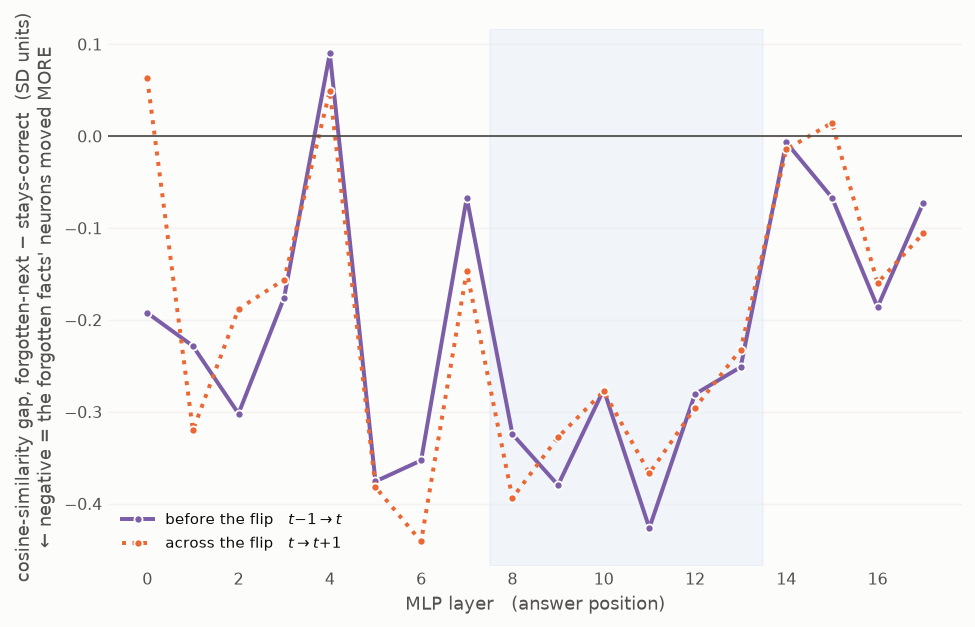

per-layer z-gap (forget − survive); negative = forgotten facts churn more
  layer       :     0     1     2     3     4     5     6     7     8     9    10    11    12    13    14    15    16    17
  before flip : -0.19 -0.23 -0.30 -0.18 +0.09 -0.38 -0.35 -0.07 -0.32 -0.38 -0.28 -0.43 -0.28 -0.25 -0.01 -0.07 -0.19 -0.07
  across flip : +0.06 -0.32 -0.19 -0.16 +0.05 -0.38 -0.44 -0.15 -0.39 -0.33 -0.28 -0.37 -0.30 -0.23 -0.01 +0.01 -0.16 -0.11
  95% CI      :   *      *      *      *      +      *      *      .      *      *      *      *      *      *      .      .      *      .  
mid-stack backward churn, z (higher = more stable neurons):
  forgotten next                                 n=  940   -0.044
  survives — just learned (wrong at t−1)         n=  649   +0.104
  survives — stably correct (correct at t−1)     n= 2376   +0.327
  survives — all  (the baseline plotted above)   n= 3025   +0.279
  gap vs ALL survivors            -0.323
  gap vs STABLY-CORRECT survivors -0.371   <- th

In [60]:
# ── Fig. 2a — per-layer churn gap, before vs across the flip  (internal §14a) ─────────
def churn_gap(Z, F, T, FG, lag_back=0, n_boot=300, seed=0):
    """Mean z-gap per layer (forget - survive) + a 95% CI bootstrapped over *facts*."""
    cur = Z[F, T - lag_back]
    gap = np.nanmean(cur[FG], 0) - np.nanmean(cur[~FG], 0)
    rng = np.random.default_rng(seed)
    uf = np.unique(F)
    pos = {f: np.where(F == f)[0] for f in uf}
    boot = np.empty((n_boot, Z.shape[2]))
    for b in range(n_boot):
        sel = np.concatenate([pos[f] for f in rng.choice(uf, uf.size, replace=True)])
        m = FG[sel]
        boot[b] = np.nanmean(cur[sel][m], 0) - np.nanmean(cur[sel][~m], 0)
    return gap, *np.percentile(boot, [2.5, 97.5], axis=0)

fig, ax1 = plt.subplots(figsize=(7.6, 4.8))
ax1.axvspan(7.5, 13.5, color=BLUE, alpha=.05, zorder=0)
for lag, col, lab, ls in ((1, PURPLE, "before the flip   $t{-}1 \\rightarrow t$", "-"),
                          (0, ORANGE, "across the flip   $t \\rightarrow t{+}1$", ":")):
    F, T, FG = (XF, XT, XFG) if lag == 0 else (AF, AT, AFG)
    g, _, _ = churn_gap(ZA_COS, F, T, FG, lag_back=lag)
    ax1.plot(xlayer, g, color=col, lw=2.2, ls=ls, marker="o", ms=4.5, mec=SURF, mew=1, label=lab)
ax1.axhline(0, color=INK2, lw=1)
ax1.set_xticks(range(0, n_mlp, 2))
ax1.set_xlabel("MLP layer   (answer position)")
ax1.set_ylabel("cosine-similarity gap, forgotten-next − stays-correct  (SD units)\n← negative = the forgotten facts' neurons moved MORE")
ax1.legend(loc="lower left", fontsize=8.5)
clean(ax1)
fig.tight_layout(); plt.show()

g_b, lo_b2, hi_b2 = churn_gap(ZA_COS, AF, AT, AFG, lag_back=1, n_boot=200)
g_c, _, _ = churn_gap(ZA_COS, XF, XT, XFG, lag_back=0, n_boot=200)
print("per-layer z-gap (forget − survive); negative = forgotten facts churn more")
print("  layer       :", " ".join(f"{i:5d}" for i in xlayer))
print("  before flip :", " ".join(f"{v:+5.2f}" for v in g_b))
print("  across flip :", " ".join(f"{v:+5.2f}" for v in g_c))
# "*" = the whole CI is below 0 (forgotten churn more); "+" = the whole CI is ABOVE 0
# (survivors churn more -- layer 4 is the one place in the stack where that happens);
# "." = the CI spans 0.
print("  95% CI      :", "  ".join("  *  " if h < 0 else ("  +  " if l > 0 else "  .  ")
                                   for l, h in zip(lo_b2, hi_b2)))

bwd = np.nanmean(ZA_COS[AF, AT - 1][:, MID], 1)

# Both groups are correct at t by construction, so "survives" already means "correct at t AND correct at t+1".  
# But over the *backward* window it silently mixes two kinds of survivor: facts that were already correct at t-1, and facts
# that were WRONG at t-1 and had just been learned -- and learning moves neurons too.  
# Splitting them shows the baseline is diluted, so the headline gap is conservative.
_was = correct[AF, AT - 1]
_grp = [("forgotten next", AFG),
        ("survives — just learned (wrong at t−1)", (~AFG) & ~_was),
        ("survives — stably correct (correct at t−1)", (~AFG) & _was),
        ("survives — all  (the baseline plotted above)", ~AFG)]
print("mid-stack backward churn, z (higher = more stable neurons):")
for nm, m in _grp:
    print(f"  {nm:46s} n={m.sum():5d}   {np.nanmean(bwd[m]):+.3f}")
print(f"  gap vs ALL survivors            {np.nanmean(bwd[AFG]) - np.nanmean(bwd[~AFG]):+.3f}")
print(f"  gap vs STABLY-CORRECT survivors {np.nanmean(bwd[AFG]) - np.nanmean(bwd[(~AFG) & _was]):+.3f}"
      f"   <- the cleaner contrast is LARGER, so the plotted gap understates the effect")

gpA = P["gold_prob"].to_numpy()[AF, AT]
gt = pd.qcut(gpA, 3, labels=False, duplicates="drop")
_w = [spearmanr(-bwd[gt == g], AFG[gt == g])[0] for g in range(3)]
_gw = [spearmanr(-gpA[gt == g], AFG[gt == g])[0] for g in range(3)]
print(f"\nrho(backward mid-stack churn, forgotten-next) = {spearmanr(-bwd, AFG)[0]:+.3f}")
print(f"  within gold-prob terciles: " + " ".join(f"{v:+.3f}" for v in _w) +
      f"   (mean {np.mean(_w):+.3f})")
print(f"  same for gold_prob itself: " + " ".join(f"{v:+.3f}" for v in _gw) +
      f"   (mean {np.mean(_gw):+.3f})")


### Fig. 2b — neurons add to the internal scalar features, they do not beat them

*Out-of-fold AUC for predicting "forgotten at the next checkpoint": 5-fold cross-validation with
the **fact** as the group, scored **inside each checkpoint** and averaged.

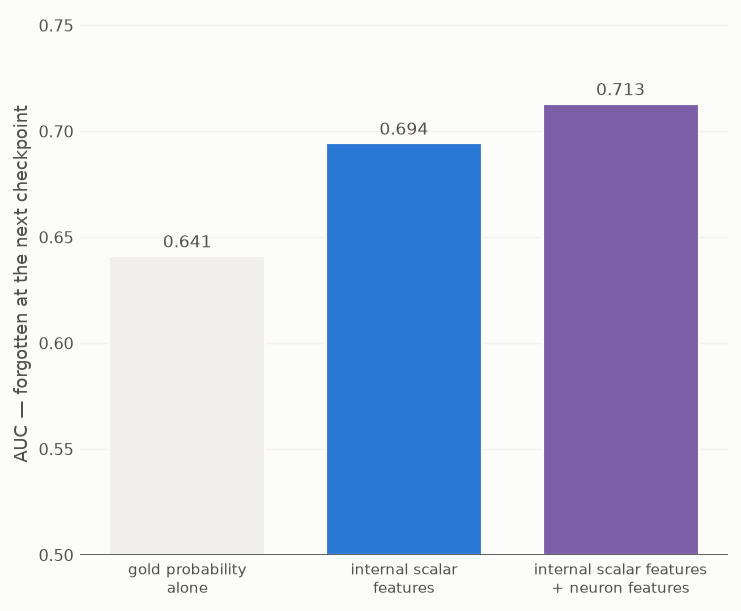


3965 ante-hoc transitions from 701 facts, base rate 23.7%
  block                      within-ckpt   pooled     per-ckpt range
  gold probability alone           0.641    0.630       [0.566, 0.736]
  internal scalar features         0.694    0.681       [0.575, 0.817]
  neuron features alone            0.685    0.711       [0.570, 0.779]
  internal scalar features + neuron features       0.713    0.740       [0.623, 0.834]
  neurons vs internal scalars: within-checkpoint -0.010, pooled +0.031
  both vs internal scalars   : within-checkpoint +0.019, pooled +0.059


In [61]:
# ── Fig. 2b — do the neurons say anything the internal scalars do not?  (internal §16) ──
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline

def band(D, key, sl, back=0):
    return np.nanmean(D[key][AF, AT - back][:, sl], 1)

OUT_SCALARS = {                       # everything the scalar analysis already had
    "gold probability":   -P["gold_prob"].to_numpy()[AF, AT],
    "gold rank":           np.log10(P["gold_rank"].to_numpy()[AF, AT] + 1.0),
    "answer margin":      -P["answer_margin"].to_numpy()[AF, AT],
    "predictive entropy":  P["pred_entropy"].to_numpy()[AF, AT],
}
NEURON_SCALARS = {                    # new, from the top-128 dump; all measured at or before t
    "churn, answer (mid)":      -np.nanmean(ZA_COS[AF, AT - 1][:, MID], 1),
    "churn, answer (early)":    -np.nanmean(ZA_COS[AF, AT - 1][:, :8], 1),
    "churn, answer (late)":     -np.nanmean(ZA_COS[AF, AT - 1][:, 14:], 1),
    "churn, subject (mid)":     -np.nanmean(ZS_COS[AF, AT - 1][:, MID], 1),
    "top-32 churn (mid)":       -np.nanmean(ZA_J32[AF, AT - 1][:, MID], 1),
    "diffuse activation (mid)":  band(NA, "PR", MID),
    "high activation entropy":   band(NA, "H", MID),
    "private neurons (mid)":    -band(NA, "GEN", MID),
    "shared neurons (late)":     band(NA, "GEN", slice(12, 16)),
    "large activation mass":     np.log10(np.clip(band(NA, "L1", MID), 1, None)),
}
X_out = np.column_stack(list(OUT_SCALARS.values()))
X_neu = np.column_stack(list(NEURON_SCALARS.values()))

def cv_oof(X):
    """Out-of-fold scores with the FACT as the group, so a fact never straddles a split.
    Imputation and scaling are fit INSIDE each training fold rather than globally."""
    X = np.asarray(X); oof = np.full(len(X), np.nan)
    for tr, te in GroupKFold(n_splits=5).split(X, AFG, groups=AF):
        m = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                          LogisticRegression(max_iter=3000)).fit(X[tr], AFG[tr])
        oof[te] = m.predict_proba(X[te])[:, 1]
    return oof

def auc_within(oof):
    """AUC computed INSIDE each checkpoint, then averaged.

    Grouping by fact stops fact leakage but NOT checkpoint leakage -- Fig. A2 makes that point
    and this panel has to obey it.  The forgetting rate runs 13%-48% across checkpoints, so a
    feature that merely encodes training time separates the pooled classes without separating
    anything within a checkpoint.  Pooled AUC is printed alongside only to show that gap.
    """
    per = [roc_auc_score(AFG[AT == t], oof[AT == t])
           for t in np.unique(AT) if 0 < AFG[AT == t].mean() < 1]
    return float(np.mean(per)), np.asarray(per)

BLOCKS = [("gold probability\nalone", X_out[:, :1], NEUTRAL),
          ("internal scalar\nfeatures", X_out, BLUE),
          ("neuron features\nalone", X_neu, ORANGE),
          ("internal scalar features\n+ neuron features",
           np.column_stack([X_out, X_neu]), PURPLE)]
SHOWN = [0, 1, 3]
oofs = [cv_oof(X) for _, X, _ in BLOCKS]
AUC_DETAIL = [auc_within(o) for o in oofs]               # the honest, checkpoint-adjusted number
aucs = [v[0] for v in AUC_DETAIL]
aucs_pooled = [roc_auc_score(AFG, o) for o in oofs]      # what pooling across checkpoints inflates it to

fig, ax2 = plt.subplots(figsize=(5.8, 4.8))
xb = list(range(len(SHOWN)))
ax2.bar(xb, [aucs[i] - .5 for i in SHOWN], bottom=.5,     # bar length = lift over chance
        color=[BLOCKS[i][2] for i in SHOWN], edgecolor=SURF, linewidth=1.2, width=.72)
for j, i in enumerate(SHOWN):
    ax2.text(j, aucs[i] + .004, f"{aucs[i]:.3f}", ha="center", fontsize=9.5, color=INK2)
ax2.axhline(0.5, color=INK2, lw=1)
ax2.set_xticks(xb, [BLOCKS[i][0] for i in SHOWN], fontsize=8.5)
ax2.set_ylim(0.5, max(aucs[i] for i in SHOWN) * 1.06)
ax2.set_ylabel("AUC — forgotten at the next checkpoint")
clean(ax2)
fig.tight_layout(); plt.show()

print(f"\n{AFG.size} ante-hoc transitions from {len(np.unique(AF))} facts, base rate {AFG.mean():.1%}")
print(f"  {'block':26s} {'within-ckpt':>11s} {'pooled':>8s} {'per-ckpt range':>18s}")
for (nm, _, _), (v, per), w in zip(BLOCKS, AUC_DETAIL, aucs_pooled):
    print(f"  {nm.replace(chr(10), ' '):26s} {v:11.3f} {w:8.3f} "
          f"      [{per.min():.3f}, {per.max():.3f}]")
print(f"  neurons vs internal scalars: within-checkpoint {aucs[2] - aucs[1]:+.3f}, "
      f"pooled {aucs_pooled[2] - aucs_pooled[1]:+.3f}")
print(f"  both vs internal scalars   : within-checkpoint {aucs[3] - aucs[1]:+.3f}, "
      f"pooled {aucs_pooled[3] - aucs_pooled[1]:+.3f}")


**What Fig. 2a does and does not establish.** The gap is negative at 17 of 18 layers (13 of
them with a bootstrap CI clear of zero), so the
doomed facts were moving more *broadly through the stack*, not in one band. Unlike Fig. 1 —
flat through boundary 7, then a clean divergence — this curve is deep at layers 1–3 and 5–6 as
well as mid-stack. The defensible claim is therefore *"instability is diffuse, and its deepest
ante-hoc point falls inside the band where the logit-lens gap has already opened"*, **not** "churn
is localised to the mid-stack". The localisation rests on Fig. 1; Fig. 2a corroborates the depth
range, not the localisation. One layer reverses: at **layer 4 the survivors churn significantly more**
(marked `+` in the printout) — the single place in the stack where movement is not a bad sign.

**Result.** The **backward** curve — measured over the interval that ended at the still-correct
checkpoint, so it cannot be an echo of the flip — is almost superimposed on the concurrent one,
and around MLP layer 11 it is *deeper*. Layer 11 writes into boundary 12, which sits inside the
0.81–0.90 plateau Figure 1 finds from boundary 10 on, so **the deepest backward neuron churn falls
inside the band where the logit-lens gap is already fully open.** Two independent measurements —
one from the output projection, one from the raw activations — agree on the region. It is *not* a
coincidence of peaks: Fig. 1 has no single peak layer (the plateau spans boundaries 10–18), so the
claim is co-location within a band, nothing sharper.

It survives conditioning on confidence, which is what makes it more than a restatement of
"weakly stored": ranking transitions by the previous interval's churn gives ρ ≈ +0.21 with
being forgotten next, and inside gold-probability terciles the mean is ≈ +0.13 against ≈ +0.06
for `gold_prob` ranked against itself the same way.

**What the predictive panel does and does not show — corrected.** Pooled across checkpoints, ten
summaries of a truncated top-128 dump with **no access to the vocabulary** reach AUC 0.711
against 0.680 for the four internal scalar features, and an earlier version of this figure reported that
as "neurons beat every output scalar combined". That comparison does not survive the checkpoint
adjustment the notebook demands elsewhere. Within checkpoints the two blocks are level — the
neuron block is 0.685 against 0.694 for the internal scalar features — so most of the pooled advantage was
the neuron features tracking *training time*, which correlates with the forgetting rate.

What does survive is the additive result, and it is the one worth reporting: **both blocks
together reach 0.713 within checkpoint against 0.694 for the internal scalar features alone, +0.019.** The
neuron dump carries information about the next flip that the output distribution does not, and
it carries it without ever seeing the vocabulary — but it is a complement to the internal scalar
features, not a replacement for them. The heading above Fig. 2b says exactly that.

**Is "survives" the right comparison group?** Both groups are correct at $t$ by construction, so
the baseline already *is* "correct and stays correct" — but only in the one-step sense, and over
the backward window that quietly mixes two kinds of survivor. The printout splits them, and the
ordering is a sanity check the figure does not otherwise get credit for:

| group at $t$ (all correct) | n | mean backward mid-stack churn (z) |
|---|---|---|
| forgotten next | 940 | **−0.044** |
| survives — just learned (wrong at $t{-}1$) | 649 | +0.104 |
| survives — stably correct (correct at $t{-}1$) | 2 376 | **+0.327** |

Churn tracks state *change in either direction*: facts that had just been **learned** sit
between the stably-correct and the doomed, because acquiring a fact moves its neurons too. That
is what a measure of genuine representational movement should do, and it means the plotted
baseline is **diluted** — against stably-correct survivors alone the gap widens from −0.323 to
**−0.371**. The headline number is therefore conservative. The one-step baseline is kept in the
figure because it is the same population Fig. 2b is scored on, which keeps the two panels
comparable; the stricter contrast belongs in the text.

**Three things to concede in the text.** The absolute numbers are modest (0.713 on a 23.7% base
rate is useful ranking, not a reliable alarm). Part of the block gain is ten features against
four — though the comparison is cross-validated with the fact as the group, so it is not
overfitting in the ordinary sense. And the effect is concentrated in the low-confidence band:
churn tells you which of the *marginal* facts will go, and adds little among facts the model
holds confidently.

A fourth, on Fig. 2a: its bootstrap resamples facts but the gap itself is still pooled over
checkpoints, so it inherits a milder version of the same mixture problem as the pooled AUC. The
per-layer *shape* is what the panel is for and that is stable; the absolute depths should be
read as descriptive.

In [62]:
# ── the hidden-state run: final-layer residuals + cross-fitted per-layer separability ──
# One streaming pass; the (1452, 19, 2048) tensors never co-reside.  Feeds Fig. 3 and A2/A3.
from sklearn.model_selection import (cross_val_predict, check_cv, KFold,
                                     StratifiedKFold, LeaveOneGroupOut)

HBASE = "data/artifacts/expermints/15shot_trajectory_top10_internal_with_hidden"
def index_by_step(pattern):          # files carry browser-download suffixes like " (1)"
    out = {}
    for f in glob.glob(pattern):
        m = re.search(r"step(\d+)", os.path.basename(f))
        if m:
            out[int(m.group(1))] = f
    return out

h_rec_files = index_by_step(f"{HBASE}/recall/*.parquet")
h_ans_files = index_by_step(f"{HBASE}/internal/hidden_step*_answer*.npy")
h_subj_files = index_by_step(f"{HBASE}/internal/hidden_step*_subject_last*.npy")
h_id_files = index_by_step(f"{HBASE}/internal/hidden_step*_ids*.npy")
STEPS = sorted(h_rec_files)
assert set(STEPS) == set(h_ans_files) == set(h_subj_files) == set(h_id_files)

IDS = np.load(h_id_files[STEPS[0]], allow_pickle=True)
recall = {s: pd.read_parquet(h_rec_files[s]) for s in STEPS}
for s in STEPS:
    assert (np.load(h_id_files[s], allow_pickle=True) == IDS).all()
    assert (recall[s]["id"].to_numpy() == IDS).all()
n_f, n_t = len(IDS), len(STEPS)

h_correct = np.column_stack([recall[s]["correct"].to_numpy().astype(bool) for s in STEPS])
scoreable = ~recall[STEPS[0]]["excluded"].to_numpy().astype(bool)
h_prop = (pd.read_csv("15_shot_top_10_trajectory_with_fact_properites.csv")
          .set_index("id").loc[IDS]["prop"].to_numpy())

def feat_matrix(col):                # (n_steps, n_facts), matching the drift/margin indexing
    return np.column_stack([pd.to_numeric(recall[s][col], errors="coerce").to_numpy()
                            for s in STEPS]).astype(float).T
h_gold_prob = feat_matrix("gold_prob")
h_answer_margin = feat_matrix("answer_margin")
h_resid_norm = feat_matrix("resid_norm_last")

def stack_layered(col):              # (n_steps, n_facts, n_layers)
    return np.stack([np.stack(recall[s][col].to_numpy()).astype(float) for s in STEPS])
act_ans = stack_layered("mlp_active_frac_by_layer")
part_ans = stack_layered("mlp_participation_by_layer")

TR_FACT, TR_T, TR_FORGET = [], [], []
for t in range(n_t - 1):
    idx = np.where(scoreable & h_correct[:, t])[0]
    TR_FACT.append(idx); TR_T.append(np.full(idx.size, t)); TR_FORGET.append(~h_correct[idx, t + 1])
TR_FACT, TR_T = np.concatenate(TR_FACT), np.concatenate(TR_T)
TR_FORGET = np.concatenate(TR_FORGET).astype(bool)

FOLD = np.random.default_rng(0).integers(0, 5, size=n_f)    # fact-level folds, fixed everywhere

def nc_auc_xfit(X, y, fold):
    """Nearest-centroid separability with centroids fit on the *other* folds."""
    if y.sum() < 10 or (~y).sum() < 10:
        return np.nan
    score = np.full(len(y), np.nan)
    for f in range(5):
        te, tr = fold == f, fold != f
        if not (y[tr].any() and (~y[tr]).any() and te.any()):
            continue
        mu_c, mu_w = X[tr & y].mean(0), X[tr & ~y].mean(0)
        score[te] = (np.linalg.norm(X[te] - mu_w, axis=1) - np.linalg.norm(X[te] - mu_c, axis=1))
    m = ~np.isnan(score)
    return roc_auc_score(y[m], score[m]) if 0 < y[m].mean() < 1 else np.nan

L_FINAL = 18
Hf_ans = np.empty((n_t, n_f, 2048), np.float32)
Hf_subj = np.empty((n_t, n_f, 2048), np.float32)
sep_xf_ans = np.full((n_t, 19), np.nan)
sep_xf_subj = np.full((n_t, 19), np.nan)

_t0 = time.time()
for ti, s in enumerate(STEPS):
    A = np.load(h_ans_files[s]).astype(np.float32)     # (n_facts, 19, 2048)
    S = np.load(h_subj_files[s]).astype(np.float32)
    Hf_ans[ti], Hf_subj[ti] = A[:, L_FINAL, :], S[:, L_FINAL, :]
    y, fo = h_correct[scoreable, ti], FOLD[scoreable]
    for L in range(19):
        sep_xf_ans[ti, L] = nc_auc_xfit(A[scoreable, L], y, fo)
        sep_xf_subj[ti, L] = nc_auc_xfit(S[scoreable, L], y, fo)
    del A, S
print(f"hidden states streamed in {time.time() - _t0:.0f}s")
print(f"{n_f} facts x {n_t} checkpoints | {scoreable.sum()} scoreable | "
      f"{TR_FORGET.size} correct->next transitions ({TR_FORGET.mean():.1%} forgotten)")
print("(this run is a separate evaluation pass from the panel above, so the transition count "
      "differs by a handful through greedy-decode noise)")

hidden states streamed in 33s
1452 facts x 13 checkpoints | 1310 scoreable | 4163 correct->next transitions (24.2% forgotten)
(this run is a separate evaluation pass from the panel above, so the transition count differs by a handful through greedy-decode noise)


---
# Figure 3 (body) — the representation was already weak before the flip

**Source:** `hidden_states_forgetting.ipynb` §12 (Fig. 3a) and
`forgetting_internal_features.ipynb` §9 (Fig. 3b).
**Papers:** Davari et al. (2022), *Probing Representation Forgetting* (CVPR); Kotha et al.
(2024), *Understanding Catastrophic Forgetting via Implicit Inference* (ICLR); Chang et al.
(2024).

### Why this figure

Figures 1–2 establish *where* and *when*. This one attacks *what kind of event a flip is*, and
it is the figure that most changes how the result should be described.

**(a) Read-out or storage?** The natural way to ask is with `is_top1` and `resolution_depth` —
but both are functions of the output distribution, so they cannot separate the two. Davari
et al.'s design can: freeze the representation and fit a **linear probe** (cross-fitted over
facts, so a fact never helps score itself).

The design has to be **paired**, and an earlier version of this figure was not. Reading the probe
only *after* the flip cannot say how much was lost: a group that was already borderline and a
group that fell off a cliff produce the same post-flip number. So the probe is read at both $t$
and $t{+}1$ for the same facts, in **probabilities** rather than through the 0.5 threshold that
discards the magnitude, and the quantity of interest is the **difference-in-differences** against
survivors. A third group — facts wrong at $t$ and still wrong at $t{+}1$ — supplies the probe's
floor, which is emphatically not 0%.

That control matters here for a second reason: every group's probe score drifts upward at
$t{+}1$, because the probe is fit at $t$ and applied to a representation that has moved 50 000
optimizer steps. The raw post-flip level is uninterpretable on its own; only the *contrast* is.

**(b) Sharpening or flattening?** Two changes produce the same binary `correct → wrong`.
*Flattening*: the whole answer distribution spreads out — gold probability falls, top-1
probability falls too, entropy **rises**. *Sharpening*: gold falls while top-1 **rises** and
entropy **falls**. That is the split the two columns actually measure, and it is all they
measure — see the caveat under the result about why it should not be called a *takeover*.

*The prompt caveat, shared with every figure here.* The flip is defined by the **15-shot** greedy
decode; the representation the probe reads, and the `top1_prob` / `pred_entropy` columns behind
Fig. 3b, are all from the **zero-shot** cloze. So Fig. 3a asks whether a *zero-shot*
representation still linearly encodes a fact whose *15-shot* decode has just failed, and Fig. 3b
describes what the *zero-shot* next-token distribution did at a flip defined elsewhere. Gold is
the zero-shot argmax for only 25.5% of flips (39.8% of all correct cells), which is the same fact
that makes the "takeover" reading untenable above. The paired design absorbs the part of this that
is constant across adjacent checkpoints; it does not make the two prompts the same measurement,
and the caption should say so.


### Fig. 3a — the gap is open *before* the flip; the flip removes nothing further

*The representation was already weak before the flip, and the flip does not weaken it further.*

A frozen-representation linear probe, cross-fitted over facts, read at **both** $t$ and $t{+}1$ for
the same facts, in probabilities. Three groups: survivors, facts forgotten at $t{+}1$, and the
never-known floor. The quantity of interest is the **difference-in-differences** (forgotten −
survivor), printed on the panel with a 95% interval from a cluster bootstrap over facts. Every
group drifts *upward* at $t{+}1$ because the probe is fit at $t$ and applied to a representation
that has moved 50 000 optimizer steps — only the contrast is interpretable.


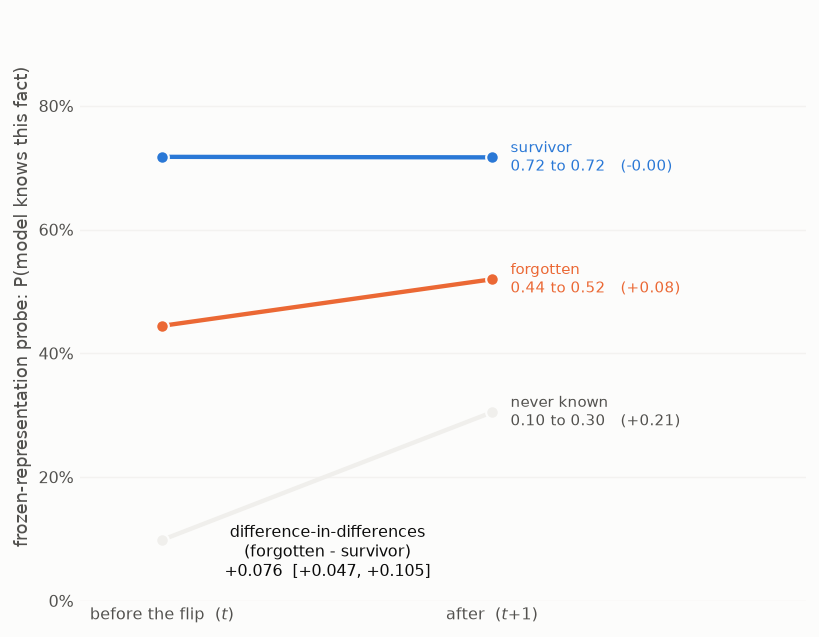

group              n  probe p at t    at t+1    change
survivor        3157         0.717     0.717    -0.001
forgotten       1006         0.444     0.520    +0.075
never known    10200         0.098     0.305    +0.207
  difference-in-differences (forgotten - survivor): +0.076 [+0.047, +0.105]  (95% cluster bootstrap over facts)
  every group drifts UP at t+1: the probe is fit at t and applied to a representation
  that has moved 50k steps, so the raw t+1 level means nothing on its own.
  threshold scale, for continuity: forgotten 51.4% 'known' at t+1 vs survivors 73.0%
  ...but the forgotten group was already at 0.444 vs 0.717 BEFORE the flip.


In [63]:
# ── Fig. 3a — representation forgetting, measured as a PAIRED change  (hidden §12) ────
# Reading the probe only at t+1 cannot say how much was lost: a group that was already
# borderline before the flip and a group that fell off a cliff give the same t+1 number.  So
# score every group at BOTH t and t+1 with the same probe (fit at t, on the other folds) and
# look at the change.  Probabilities, not `predict`, because the 0.5 threshold discards exactly
# the magnitude the question is about.  Three groups, including the never-known floor -- the
# probe's null, which is emphatically not 0%.
sc_t, sc_t1, grp, fact_of = [], [], [], []
for t in range(n_t - 1):
    for f in range(5):
        tr = scoreable & (FOLD != f)
        c = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, C=0.05))
        c.fit(Hf_ans[t][tr], h_correct[tr, t])
        held = scoreable & (FOLD == f)
        hcur = held & h_correct[:, t]
        for m, g in ((hcur & h_correct[:, t + 1], "survivor"),
                     (hcur & ~h_correct[:, t + 1], "forgotten"),
                     (held & ~h_correct[:, t] & ~h_correct[:, t + 1], "never known")):
            if m.any():
                sc_t.append(c.predict_proba(Hf_ans[t][m])[:, 1])
                sc_t1.append(c.predict_proba(Hf_ans[t + 1][m])[:, 1])
                grp.append(np.full(m.sum(), g))
                fact_of.append(np.where(m)[0])
sc_t, sc_t1, grp, fact_of = (np.concatenate(x) for x in (sc_t, sc_t1, grp, fact_of))
GRPS = ("survivor", "forgotten", "never known")
P_T = {g: sc_t[grp == g].mean() for g in GRPS}
P_T1 = {g: sc_t1[grp == g].mean() for g in GRPS}
DELTA = {g: P_T1[g] - P_T[g] for g in GRPS}
DID = DELTA["forgotten"] - DELTA["survivor"]      # the flip's own effect on the representation
# CI on the DiD, resampling FACTS (a fact contributes several transitions, so its rows are not
# independent).  Without this the DiD is a point estimate and the "removes nothing" claim has
# no error bar to stand on.
_d = sc_t1 - sc_t
_rng = np.random.default_rng(0)
_uf = np.unique(fact_of)
_pos = {f: np.where(fact_of == f)[0] for f in _uf}
_bt = []
for _ in range(1000):
    _sel = np.concatenate([_pos[f] for f in _rng.choice(_uf, _uf.size, replace=True)])
    _g = grp[_sel]
    if (_g == "forgotten").any() and (_g == "survivor").any():
        _bt.append(_d[_sel][_g == "forgotten"].mean() - _d[_sel][_g == "survivor"].mean())
DID_LO, DID_HI = np.percentile(_bt, [2.5, 97.5])
still_known = sc_t1[grp == "forgotten"] > .5      # threshold-scale, for continuity with the text
ctrl_known = sc_t1[grp == "survivor"] > .5

fig, ax1 = plt.subplots(figsize=(6.4, 5.0))
COLS = {"survivor": BLUE, "forgotten": ORANGE, "never known": NEUTRAL}
for g in GRPS:
    ax1.plot([0, 1], [P_T[g], P_T1[g]], color=COLS[g], lw=2.4, marker="o", ms=7,
             mec=SURF, mew=1.2, zorder=3)
    ax1.annotate(f"{g}\n{P_T[g]:.2f} to {P_T1[g]:.2f}   ({DELTA[g]:+.2f})",
                 (1, P_T1[g]), xytext=(10, 0), textcoords="offset points",
                 va="center", fontsize=8.5,
                 color=(COLS[g] if g != "never known" else INK2))
ax1.text(0.5, 0.04, f"difference-in-differences\n(forgotten - survivor)\n{DID:+.3f}  [{DID_LO:+.3f}, {DID_HI:+.3f}]",
         ha="center", fontsize=9, color=INK)
ax1.set_xlim(-0.25, 1.95)
ax1.set_ylim(0, 0.95)
ax1.set_xticks([0, 1], ["before the flip  ($t$)", "after  ($t{+}1$)"], fontsize=9)
ax1.yaxis.set_major_formatter(PCT)
ax1.set_ylabel("frozen-representation probe: P(model knows this fact)")
clean(ax1)
fig.tight_layout(); plt.show()

print(f"{'group':13s} {'n':>6s} {'probe p at t':>13s} {'at t+1':>9s} {'change':>9s}")
for g in GRPS:
    print(f"{g:13s} {(grp == g).sum():6d} {P_T[g]:13.3f} {P_T1[g]:9.3f} {DELTA[g]:+9.3f}")
print(f"  difference-in-differences (forgotten - survivor): {DID:+.3f} "
      f"[{DID_LO:+.3f}, {DID_HI:+.3f}]  (95% cluster bootstrap over facts)")
print("  every group drifts UP at t+1: the probe is fit at t and applied to a representation")
print("  that has moved 50k steps, so the raw t+1 level means nothing on its own.")
print(f"  threshold scale, for continuity: forgotten {still_known.mean():.1%} 'known' at t+1 vs "
      f"survivors {ctrl_known.mean():.1%}")
print(f"  ...but the forgotten group was already at {P_T['forgotten']:.3f} vs "
      f"{P_T['survivor']:.3f} BEFORE the flip.")


### Fig. 3b — two regimes, and half of all flips reverse by $t{+}2$

*Every forgetting event, by what the zero-shot answer distribution did at the flip.* Flattening =
top-1 probability falls and entropy rises; sharpening = top-1 rises and entropy falls. The
relearned-by-$t{+}2$ rates and the share of the sharpening group in which gold was the zero-shot
top-1 beforehand are annotated in the panel — the latter is why this is *sharpening*, not a
*takeover*.


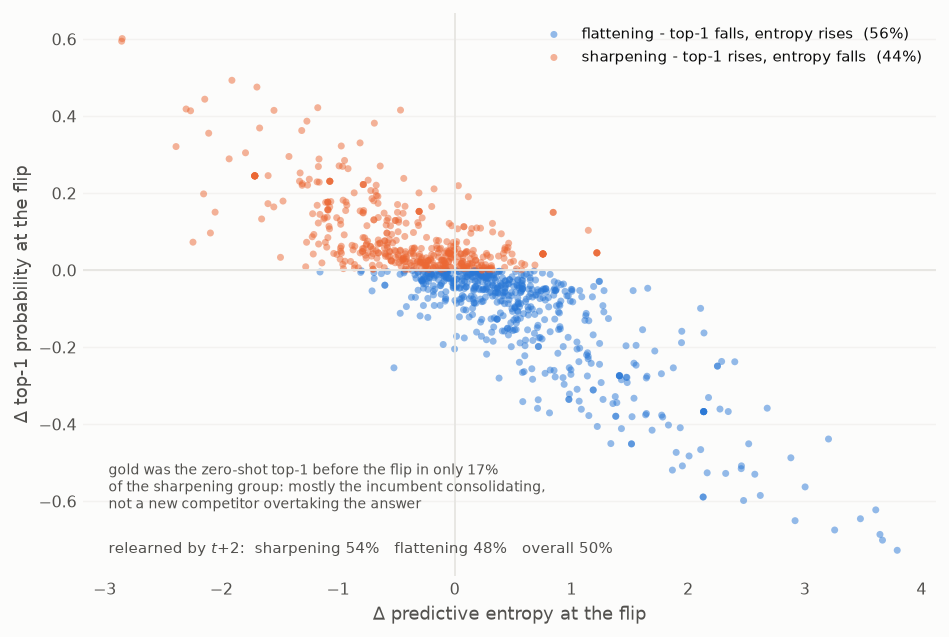

1003 forgetting events
  sharpening (top-1 rises): 44.2%  median dtop1=+0.0502  dentropy=-0.420
  flattening (top-1 falls): 55.8%  median dtop1=-0.0656  dentropy=+0.461
  gold was the zero-shot top-1 before the flip: 25.5% overall, 16.9% within the sharpening group
  overall median dentropy at the flip: +0.101  (> 0 => net flattening)
  relearned by t+2: overall 50.3% | sharpening 53.5% vs flattening 47.8%


In [64]:
# ── Fig. 3b — sharpening vs flattening at the flip  (internal §9) ─────────────────────
ev_f, ev_t = np.where(correct[:, :-1] & ~correct[:, 1:])
d_top1 = NEWP["top1_prob"][ev_f, ev_t + 1] - NEWP["top1_prob"][ev_f, ev_t]
d_ent = NEWP["pred_entropy"][ev_f, ev_t + 1] - NEWP["pred_entropy"][ev_f, ev_t]
sharpen = d_top1 > 0                      # the argmax became more probable
# Was gold the incumbent before the flip?  Decides whether "sharpening" can be read as a
# competitor TAKING OVER from the gold answer, or only as the existing winner consolidating.
gold_was_top1 = np.column_stack([fr["is_top1"].to_numpy().astype(bool)
                                 for fr in _frames])[ev_f, ev_t]
back = np.array([correct[f, t + 2] if t + 2 < n_steps else np.nan
                 for f, t in zip(ev_f, ev_t)], float)

fig, ax2 = plt.subplots(figsize=(7.4, 5.0))
ax2.axhline(0, color=GRID, lw=1); ax2.axvline(0, color=GRID, lw=1)
# Naming: these are what the two columns literally measure.  "Takeover" would claim a specific
# competitor overtook the gold token at the flip -- but gold was the zero-shot argmax at t in
# only ~17% of this group, so in the rest the winner was already non-gold and merely gained
# confidence.  Sharpening vs flattening is the claim the data supports.
ax2.scatter(d_ent[~sharpen], d_top1[~sharpen], s=15, color=BLUE, alpha=.5, edgecolor="none",
            label=f"flattening - top-1 falls, entropy rises  ({(~sharpen).mean():.0%})")
ax2.scatter(d_ent[sharpen], d_top1[sharpen], s=15, color=ORANGE, alpha=.5, edgecolor="none",
            label=f"sharpening - top-1 rises, entropy falls  ({sharpen.mean():.0%})")
ax2.set_xlabel("Δ predictive entropy at the flip")
ax2.set_ylabel("Δ top-1 probability at the flip")
ax2.legend(loc="upper right", fontsize=8.5)
ax2.annotate(f"relearned by $t{{+}}2$:  sharpening {np.nanmean(back[sharpen]):.0%}   "
             f"flattening {np.nanmean(back[~sharpen]):.0%}   overall {np.nanmean(back):.0%}",
             (0.03, 0.04), xycoords="axes fraction", fontsize=8.5, color=INK2)
ax2.text(0.03, 0.12, f"gold was the zero-shot top-1 before the flip in only "
         f"{gold_was_top1[sharpen].mean():.0%}\nof the sharpening group: mostly the incumbent "
         f"consolidating,\nnot a new competitor overtaking the answer",
         transform=ax2.transAxes, fontsize=7.5, color=INK2)
clean(ax2)
fig.tight_layout(); plt.show()

print(f"{len(ev_f)} forgetting events")
print(f"  sharpening (top-1 rises): {sharpen.mean():5.1%}  median dtop1={np.median(d_top1[sharpen]):+.4f}"
      f"  dentropy={np.median(d_ent[sharpen]):+.3f}")
print(f"  flattening (top-1 falls): {(~sharpen).mean():5.1%}  median dtop1={np.median(d_top1[~sharpen]):+.4f}"
      f"  dentropy={np.median(d_ent[~sharpen]):+.3f}")
print(f"  gold was the zero-shot top-1 before the flip: {gold_was_top1.mean():.1%} overall, "
      f"{gold_was_top1[sharpen].mean():.1%} within the sharpening group")
print(f"  overall median dentropy at the flip: {np.median(d_ent):+.3f}  (> 0 => net flattening)")
print(f"  relearned by t+2: overall {np.nanmean(back):.1%} | sharpening {np.nanmean(back[sharpen]):.1%}"
      f" vs flattening {np.nanmean(back[~sharpen]):.1%}")


**Result — and it is not the result an earlier draft reported.** The paired reading overturns the
"half of it survives" framing. Measured as probe probabilities:

| group at $t$ | n | before the flip | after | change |
|---|---|---|---|---|
| survivors | 3 157 | 0.717 | 0.717 | **−0.001** |
| forgotten | 1 006 | **0.444** | 0.520 | +0.075 |
| never known (floor) | 10 200 | 0.098 | 0.305 | +0.207 |

The gap between forgotten and surviving facts is **fully open before the flip** — 0.444 against
0.717 — and the flip itself removes nothing: the difference-in-differences is **+0.076** (95% cluster
bootstrap over facts [+0.047, +0.105]) — if anything in the wrong direction, and its interval
excludes any loss. On the raw threshold scale the old numbers still appear (51.4%
of forgotten facts called "known" at $t{+}1$ against 73.0% of survivors), but that 51-vs-73 gap
is a **pre-existing** difference, not something the forgetting event produces. Reading it as
"representation forgetting" was reading a cross-section as a change.

So the honest claim is stronger for the paper, not weaker, and it agrees with Figures 1 and 2: a
flip is the visible crossing of a threshold the fact was **already sitting on**. Nothing is
erased at the moment of forgetting. The wording "represented but not emitted" should be struck —
it implied an intact representation with a broken read-out, and what the data shows is a
*weak* representation whose output happened to tip.

Fig. 3b splits the events by what the output distribution did: **44% sharpen** (top-1
probability rises by a median +0.05 while entropy *falls* 0.42 nats) and **56% flatten** (top-1
falls, entropy rises 0.46 nats). The aggregate entropy change is mildly positive, so averaging
the two regimes reads as "flattening" and hides that nearly half of all forgetting sharpens.

**Do not call the sharpening group a takeover.** `d_top1 > 0` says the argmax became more
probable; it does not say a *competitor overtook the gold answer*. Gold was the zero-shot top-1
before the flip in only **16.9%** of that group (25.5% of all flips), so in the large majority
the winner was already a non-gold token that merely gained confidence. Establishing a Kotha-style
takeover would need the identity of the winning token tracked across the flip, which these two
columns cannot do. The regime does **not** predict recovery: ≈54% of sharpening and ≈48% of
flattening events are correct again two checkpoints later. That half of all forgetting events
reverse within one checkpoint is itself a headline — this is oscillation around a threshold far
more than it is erasure.

**Caveat for the caption.** Figure A3 shows a substantial part of the probe's signal is
lexical/relation identity, which does not change between adjacent checkpoints. That is exactly
why the paired design is necessary: the static component cancels in the difference, so the DiD is
the only number here that is not contaminated by it.


---
---
# Appendix figures

## Figure A1 — the layer geography of a fact's neurons

**Source:** `forgetting_internal_features.ipynb` §13.
**Papers:** Geva et al. (2021), *FFN Layers Are Key-Value Memories*; Dai et al. (2022),
*Knowledge Neurons*; Gurnee et al. (2023), *Finding Neurons in a Haystack*; Elhage et al.
(2022), *Toy Models of Superposition*.

**Why the appendix.** Figures 1 and 2 both shade "layers 8–13" and call it the mid-stack. That
band has to be *derived* somewhere rather than asserted, and the derivation is descriptive enough
that it does not earn a body slot. It also comes out weaker than an earlier draft claimed: of the
three properties below, **only genericity has its extremum inside the band**. Sparsity keeps
increasing past it and volatility peaks before it, so the band is a *privacy* band — the layers
where a fact runs on units few other facts touch — not a sparse-and-volatile one. Three properties
per layer, at both token positions:

- **participation ratio** $(\sum|a|)^2 / \sum a^2$ — the *effective* number of neurons carrying
  the activation. Low = a few units dominate.
- **genericity** — the average share of the other 1 309 facts that also have this fact's top-128
  neurons in *their* top-128. High = the fact rides on units everybody uses; low = the units are
  close to private to it. This is the observable superposition axis, measured over facts rather
  than tokens.
- **stability** — the cosine between consecutive checkpoints' sparse activation vectors.

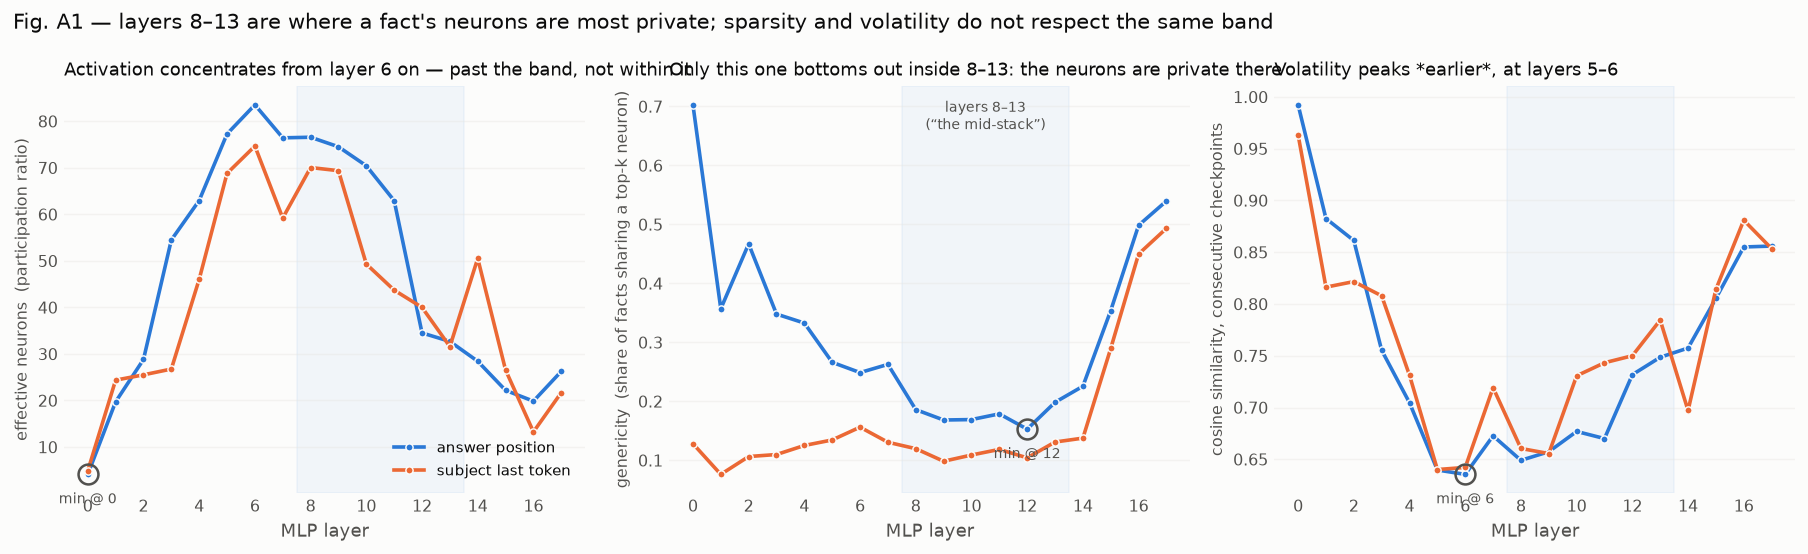

answer-position extrema:  participation peaks @ layer 6 and bottoms out @ layer 16 (after the peak);  genericity min @ layer 12;  stability min @ layer 6
  -> only genericity's minimum falls inside the 8-13 band; the band is a PRIVACY band, not a sparsity or volatility one

layer  PR(ans)  GEN(ans)  cos(ans)  PR(subj)  cos(subj)
    0      4.1     0.703     0.992       4.9      0.963
    1     19.7     0.357     0.882      24.4      0.816
    2     28.8     0.467     0.861      25.5      0.822
    3     54.5     0.348     0.755      26.7      0.808
    4     63.0     0.333     0.705      46.0      0.731
    5     77.3     0.266     0.640      68.8      0.640
    6     83.5     0.249     0.635      74.7      0.642
    7     76.4     0.263     0.673      59.2      0.719
    8     76.6     0.186     0.649      70.0      0.660
    9     74.5     0.168     0.657      69.4      0.656
   10     70.4     0.169     0.677      49.3      0.731
   11     62.9     0.179     0.670      43.7      0.7

In [65]:
# ── Fig. A1 — where the top-128 neurons live  (internal §13) ──────────────────────────
# Only ONE of the three properties actually has its extremum inside 8-13, and the titles say
# which.  Participation keeps falling past the band (min at layer 16) and volatility peaks
# *before* it (min cosine at layers 5-6), so genericity is the property that defines the band.
PANELS = [("PR",  "effective neurons  (participation ratio)",
           "Activation concentrates from layer 6 on — past the band, not within it"),
          ("GEN", "genericity  (share of facts sharing a top-k neuron)",
           "Only this one bottoms out inside 8–13: the neurons are private there"),
          ("COS", "cosine similarity, consecutive checkpoints",
           "Volatility peaks *earlier*, at layers 5–6")]

fig, axes = plt.subplots(1, 3, figsize=(14, 4.3))
for ax, (key, ylab, title) in zip(axes, PANELS):
    for D, col, name in ((NA, BLUE, "answer position"), (NS, ORANGE, "subject last token")):
        y = np.nanmedian(D[key].reshape(-1, n_mlp), 0)
        ax.plot(xlayer, y, color=col, lw=2, marker="o", ms=4, mec=SURF, mew=.8, label=name)
        if D is NA:                       # mark where the answer-position curve truly bottoms out
            am = int(np.nanargmin(y))
            ax.plot(am, y[am], "o", ms=11, mfc="none", mec=INK2, mew=1.4, zorder=4)
            ax.annotate(f"min @ {am}", (am, y[am]), xytext=(0, -16), textcoords="offset points",
                        ha="center", fontsize=8, color=INK2)
    ax.axvspan(7.5, 13.5, color=BLUE, alpha=.05, zorder=0)
    ax.set_xticks(range(0, n_mlp, 2))
    ax.set_xlabel("MLP layer")
    ax.set_ylabel(ylab, fontsize=9)
    ax.set_title(title, loc="left", fontsize=10)
    clean(ax)
axes[0].legend(loc="lower right", fontsize=8.5)
axes[1].text(10.5, axes[1].get_ylim()[1] * .97, "layers 8–13\n(“the mid-stack”)",
             fontsize=8, color=INK2, ha="center", va="top")
fig.suptitle("Fig. A1 — layers 8–13 are where a fact's neurons are most private; sparsity and "
             "volatility do not respect the same band", x=0.01, ha="left", fontsize=11.5)
fig.tight_layout(); plt.show()

_pr = np.array([np.nanmedian(NA['PR'][:, :, l]) for l in range(n_mlp)])
_gen = np.array([np.nanmedian(NA['GEN'][:, :, l]) for l in range(n_mlp)])
_cos = np.array([np.nanmedian(NA['COS'][:, :, l]) for l in range(n_mlp)])
_pk = int(_pr.argmax())                       # participation peaks mid-early, then falls away
print("answer-position extrema:  participation peaks @ layer {:d} and bottoms out @ layer {:d}"
      " (after the peak);  genericity min @ layer {:d};  stability min @ layer {:d}"
      .format(_pk, _pk + int(_pr[_pk:].argmin()), int(_gen.argmin()), int(_cos.argmin())))
print("  -> only genericity's minimum falls inside the 8-13 band; "
      "the band is a PRIVACY band, not a sparsity or volatility one")
print()
print(f"{'layer':>5s} {'PR(ans)':>8s} {'GEN(ans)':>9s} {'cos(ans)':>9s} {'PR(subj)':>9s} {'cos(subj)':>10s}")
for l in range(n_mlp):
    print(f"{l:5d} {np.nanmedian(NA['PR'][:,:,l]):8.1f} {np.nanmedian(NA['GEN'][:,:,l]):9.3f} "
          f"{np.nanmedian(NA['COS'][:,:,l]):9.3f} {np.nanmedian(NS['PR'][:,:,l]):9.1f} "
          f"{np.nanmedian(NS['COS'][:,:,l]):10.3f}")

**Result.** The stack is roughly three-part, but the three properties do **not** agree on where
the middle is, and the honest reading is narrower than "sparse, private and volatile".

Layers 0–2 and 15–17 are *generic and stable* — a third to two-thirds of all facts share a
top-128 neuron there (0.70 at layer 0), and consecutive checkpoints agree at cosine 0.81–0.99.
These are format/vocabulary layers, not fact storage. Then the three curves part company:

| property | where it actually extremises | inside 8–13? |
|---|---|---|
| participation ratio | rises to ≈84 effective neurons at layer 6, then falls steadily to **≈20 at layer 16** | no — it passes *through* the band and keeps going |
| **genericity** | **0.153 at layer 12**, the minimum anywhere in the stack | **yes** |
| stability (cosine) | minimum **0.635 at layer 6**, with layer 5 at 0.640 — both below every layer in 8–13 (min 0.649) | no — volatility peaks *before* the band |

So the claim the body figures can lean on is the genericity one: **layers 8–13 are where a fact's
top-128 neurons are least shared with other facts.** That is still the Geva et al. (2021) /
Dai et al. (2022) knowledge-neuron signature in its load-bearing part — private units, addressed
by the subject — and it is what makes "the same neurons for the same fact" a meaningful statement
in Fig. 2 and A4. But "sparsest" and "least stable" belong to layers 6 and 5–6 respectively, and
an earlier draft asserting all three of the band was over-reading its own table.

This is a weaker convergence with Figure 1 than previously claimed. Figure 1 puts the onset of the
logit-lens failure at boundary 8 from the output side; A1 localises *privacy* to MLP layers
8–13 from the activation side. Those agree, and the shading in the body figures is drawn from
that agreement — but participation and stability are not part of the argument and should not be
cited as if they were.

---
## Figure A2 — a cross-validation audit that overturns a conclusion

**Source:** `hidden_states_forgetting.ipynb` §8.
**Papers:** Hewitt & Liang (2019), *Designing and Interpreting Probes with Control Tasks*;
Timkey & van Schijndel (2021), *All Bark and No Bite: Rogue Dimensions*.

**Why the appendix.** An earlier draft of this analysis concluded that the raw 2048-d residual
vector is "essentially non-predictive (AUC ≈ 0.48)" of which correct facts slip, and built a
headline on it: *fragility is a boundary distance, not a direction.* That rests entirely on one
line — `cross_val_predict(clf, X, y, cv=5)`.

The obvious diagnosis is wrong, and the right one is more specific. An integer `cv` does **not**
mean `KFold`: for a classifier, `check_cv` returns **`StratifiedKFold(shuffle=False)`**. The
control settles which half of that matters — a genuine unshuffled `KFold(5)` on the same rows
scores **0.703**, essentially the leak-free number. So holding out contiguous checkpoints is not
what breaks it; **stratifying** is.

The mechanism: the transition rows are built by looping over checkpoints, so they arrive sorted
by training time, and the forgetting base rate swings from 13% to 48% across checkpoints.
Stratification forces every fold to the same 24.2% base rate, which means the positive and the
negative class must be cut at **different checkpoints**. Inside every test fold the forgotten
rows then come from systematically *earlier* checkpoints than the survivors (skew −0.3 to −2.2,
printed below), and the training folds carry the mirror image. A 2048-d probe can read the
checkpoint off the residual stream, so it learns "later checkpoint ⇒ forgotten" on the training
folds and meets the opposite relation on the test fold. That is why the score lands *below* 0.5
rather than at it — a plain 50/50 failure would sit at chance. Plain `KFold` cuts both classes at
the same rows, its skew is ≈0, and it is fine.

There is a real problem hiding underneath that cuts the other way: with *random* folds a
high-dimensional probe can identify **which checkpoint** a vector came from and just predict
that checkpoint's base rate. So neither scheme is trustworthy, and the alternatives are compared:

| scheme | leakage risk |
|---|---|
| `StratifiedKFold` unshuffled (**the original**, what `cv=5` gives) | the two classes are cut at different checkpoints → anti-correlated split, scores below chance |
| plain unshuffled `KFold` (the control) | none, and in fact fine here — isolates stratification as the culprit |
| random `KFold(shuffle=True)` | one fact appears in ≤ 12 rows → **fact leakage** |
| `GroupKFold` by fact id | fixes fact leakage; **checkpoint base rate still leaks** |
| leave-one-checkpoint-out, scored within checkpoint | **fact leakage**: ~97% of held-out rows have their own fact in the training checkpoints |
| **`GroupKFold` by fact, then AUC scored *inside* each checkpoint** | neither — the honest number |

Three controls the original bar chart lacked are added: `resid_norm_last` alone (is the
"geometry" just vector length?), a **whitened** margin with the top 3 principal components
removed, and a **cross-fitted** margin whose centroids exclude the scored fact.

audit in 18s


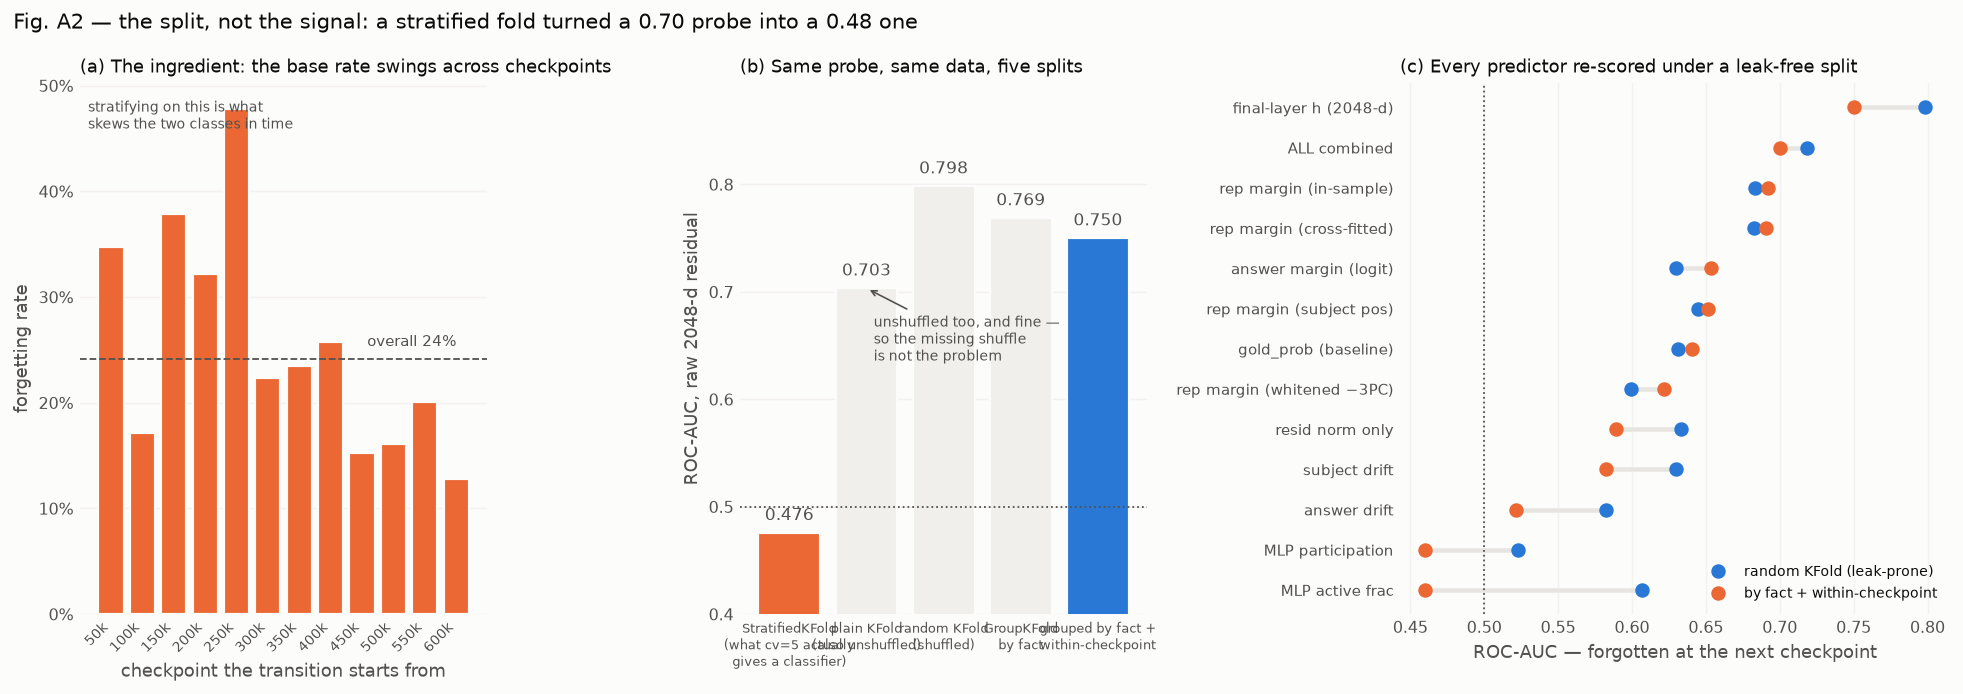

rows sorted by checkpoint? True -> any unshuffled split cuts along training time
cv=5 on a classifier resolves to StratifiedKFold(shuffle=False), NOT KFold
  2048-d probe, StratifiedKFold(5) 0.476  vs plain KFold(5) 0.703   <- the missing shuffle is not what breaks it
  per-fold mean-checkpoint skew, forgotten minus survivors:
    StratifiedKFold : -0.31 -1.54 -2.22 -1.64 -0.55
    plain KFold     : +0.15 -0.01 +0.09 +0.36 -0.00
  and the checkpoint composition of each StratifiedKFold test fold:
    fold 0: mean t= 1.37  range 0-3  largest single-checkpoint share 36.9%
    fold 1: mean t= 4.35  range 2-6  largest single-checkpoint share 27.3%
    fold 2: mean t= 6.70  range 4-8  largest single-checkpoint share 33.9%
    fold 3: mean t= 8.79  range 6-10  largest single-checkpoint share 50.5%
    fold 4: mean t=10.52  range 9-11  largest single-checkpoint share 57.2%
rep_margin in-sample vs cross-fitted: r = 0.9981

feature                         orig KFold   randCV  groupCV  within-ckp

In [66]:
# ── Fig. A2 — the CV audit  (hidden §8) ──────────────────────────────────────────────
def cos_drift(H):
    Hn = H / (np.linalg.norm(H, axis=2, keepdims=True) + 1e-8)
    return 1.0 - np.einsum("tfd,tfd->tf", Hn[:-1], Hn[1:])
drift_ans, drift_subj = cos_drift(Hf_ans), cos_drift(Hf_subj)

def _xfit_margin(H_all):
    """Nearest-centroid margin whose centroids are built WITHOUT the scored fact."""
    out = np.full((n_t, n_f), np.nan)
    for ti in range(n_t):
        H = H_all[ti]
        for f in range(5):
            te, tr = FOLD == f, (FOLD != f) & scoreable
            mu_c, mu_w = H[tr & h_correct[:, ti]].mean(0), H[tr & ~h_correct[:, ti]].mean(0)
            out[ti, te] = (np.linalg.norm(H[te] - mu_w, axis=1)
                           - np.linalg.norm(H[te] - mu_c, axis=1))
    return out

rep_margin = np.full((n_t, n_f), np.nan)                 # the in-sample version, for comparison
for ti in range(n_t):
    y, w = h_correct[:, ti] & scoreable, (~h_correct[:, ti]) & scoreable
    mu_c, mu_w = Hf_ans[ti][y].mean(0), Hf_ans[ti][w].mean(0)
    rep_margin[ti] = (np.linalg.norm(Hf_ans[ti] - mu_w, axis=1)
                      - np.linalg.norm(Hf_ans[ti] - mu_c, axis=1))
rep_margin_xf = _xfit_margin(Hf_ans)
rep_margin_subj = _xfit_margin(Hf_subj)

rep_margin_wh = np.full((n_t, n_f), np.nan)              # standardise dims, project out top-3 PCs
for ti in range(n_t):
    H = Hf_ans[ti]
    mu, sd = H[scoreable].mean(0), H[scoreable].std(0) + 1e-6
    Hw = (H - mu) / sd
    Hs = Hw[scoreable]
    V = np.linalg.svd(Hs - Hs.mean(0), full_matrices=False)[2][:3]
    Hp = Hw - (Hw @ V.T) @ V
    for f in range(5):
        te, tr = FOLD == f, (FOLD != f) & scoreable
        mu_c, mu_w = Hp[tr & h_correct[:, ti]].mean(0), Hp[tr & ~h_correct[:, ti]].mean(0)
        rep_margin_wh[ti, te] = (np.linalg.norm(Hp[te] - mu_w, axis=1)
                                 - np.linalg.norm(Hp[te] - mu_c, axis=1))

NW_FEATS = {
    "gold_prob (baseline)":       h_gold_prob[TR_T, TR_FACT],
    "answer margin (logit)":      h_answer_margin[TR_T, TR_FACT],
    "answer drift":               drift_ans[TR_T, TR_FACT],
    "subject drift":              drift_subj[TR_T, TR_FACT],
    "rep margin (in-sample)":     rep_margin[TR_T, TR_FACT],
    "rep margin (cross-fitted)":  rep_margin_xf[TR_T, TR_FACT],
    "rep margin (whitened −3PC)": rep_margin_wh[TR_T, TR_FACT],
    "rep margin (subject pos)":   rep_margin_subj[TR_T, TR_FACT],
    "resid norm only":            h_resid_norm[TR_T, TR_FACT],
    "MLP active frac":            np.nanmean(act_ans, 2)[TR_T, TR_FACT],
    "MLP participation":          np.nanmean(part_ans, 2)[TR_T, TR_FACT],
}
NW_X = np.column_stack(list(NW_FEATS.values()))
NW_OK = np.isfinite(NW_X).all(1)
NW_X, NW_Y = NW_X[NW_OK], TR_FORGET.astype(int)[NW_OK]
NW_G, NW_TT = TR_FACT[NW_OK], TR_T[NW_OK]
NW_H = Hf_ans[TR_T, TR_FACT][NW_OK]

def _score(Xc, cv, groups=None):
    Xc = Xc.reshape(len(Xc), -1)
    clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
    return cross_val_predict(clf, Xc, NW_Y, cv=cv, groups=groups, method="predict_proba")[:, 1]

def four_schemes(Xc):
    a = roc_auc_score(NW_Y, _score(Xc, 5))                                    # the original
    b = roc_auc_score(NW_Y, _score(Xc, KFold(5, shuffle=True, random_state=0)))
    c = roc_auc_score(NW_Y, _score(Xc, GroupKFold(5), NW_G))
    # BOTH controls at once.  Leave-one-checkpoint-out was the previous "leak-free" scheme, but
    # holding out a checkpoint does not hold out a FACT: ~97% of the held-out rows have their own
    # fact present in the training checkpoints, so fact identity leaks straight through it.
    # Grouping by fact removes that; scoring inside each checkpoint removes the base-rate/clock
    # confound.  Neither alone is enough, and this column is the only honest number here.
    p = _score(Xc, GroupKFold(5), NW_G)
    w = np.nanmean([roc_auc_score(NW_Y[NW_TT == t], p[NW_TT == t])
                    for t in range(n_t - 1) if 0 < NW_Y[NW_TT == t].mean() < 1])
    return a, b, c, w

_t0 = time.time()
AUDIT = {k: four_schemes(NW_X[:, [i]]) for i, k in enumerate(NW_FEATS)}
AUDIT["ALL combined"] = four_schemes(NW_X)
AUDIT["final-layer h (2048-d)"] = four_schemes(NW_H)

# The control that isolates WHICH property of the original split does the damage.  `cv=5` with a
# classifier is StratifiedKFold(shuffle=False), not KFold -- the original scheme was unshuffled
# AND stratified, and only one of the two is responsible.
KF_PLAIN = roc_auc_score(NW_Y, _score(NW_H, KFold(5, shuffle=False)))

def fold_time_skew(cvv):
    """Per test fold: mean checkpoint of the forgotten rows minus that of the survivors.  Non-zero
    means the two classes are drawn from different points in training, so anything that can read
    the checkpoint off the residual learns a sign on the training folds that reverses on the test
    fold -- which is how an AUC lands *below* chance rather than at it."""
    return np.array([NW_TT[te][NW_Y[te] == 1].mean() - NW_TT[te][NW_Y[te] == 0].mean()
                     for _, te in cvv.split(NW_X, NW_Y)])
SKEW_STRAT, SKEW_PLAIN = fold_time_skew(StratifiedKFold(5)), fold_time_skew(KFold(5))
print(f"audit in {time.time() - _t0:.0f}s")

rate_by_ckpt = np.array([TR_FORGET[TR_T == t].mean() for t in range(n_t - 1)])
fig, (axA, axB, axC) = plt.subplots(1, 3, figsize=(15.2, 5.4),
                                    gridspec_kw={"width_ratios": [1, 1, 1.35]})
axA.bar(range(n_t - 1), rate_by_ckpt, color=ORANGE, edgecolor=SURF, linewidth=1.2)
axA.axhline(TR_FORGET.mean(), color=INK2, ls="--", lw=1)
axA.text(n_t - 2, TR_FORGET.mean() + .012, f"overall {TR_FORGET.mean():.0%}",
         ha="right", fontsize=8.5, color=INK2)
axA.set_xticks(range(n_t - 1), [f"{STEPS[t]//1000}k" for t in range(n_t - 1)],
               rotation=45, ha="right", fontsize=8)
axA.yaxis.set_major_formatter(PCT)
axA.set_xlabel("checkpoint the transition starts from")
axA.set_ylabel("forgetting rate")
axA.set_title("(a) The ingredient: the base rate swings across checkpoints",
              loc="left", fontsize=10)
axA.text(0.02, 0.97, "stratifying on this is what\nskews the two classes in time",
         transform=axA.transAxes, fontsize=7.5, color=INK2, va="top")

_a, _b, _c, _w = AUDIT["final-layer h (2048-d)"]
schemes = ["StratifiedKFold\n(what cv=5 actually\ngives a classifier)",
           "plain KFold\n(also unshuffled)", "random KFold\n(shuffled)",
           "GroupKFold\nby fact", "grouped by fact +\nwithin-checkpoint"]
vals = [_a, KF_PLAIN, _b, _c, _w]
axB.bar(range(5), vals, color=[ORANGE, NEUTRAL, NEUTRAL, NEUTRAL, BLUE],
        edgecolor=SURF, linewidth=1.2)
axB.axhline(0.5, color=INK2, ls=":", lw=1)
for i, v in enumerate(vals):
    axB.text(i, v + .012, f"{v:.3f}", ha="center", fontsize=9.5, color=INK2)
axB.annotate("unshuffled too, and fine —\nso the missing shuffle\nis not the problem",
             (1, KF_PLAIN), xytext=(4, -40), textcoords="offset points", ha="left",
             fontsize=7.5, color=INK2,
             arrowprops=dict(arrowstyle="->", color=INK2, lw=.9))
axB.set_xticks(range(5), schemes, fontsize=7)
axB.set_ylim(0.4, max(vals) * 1.12)
axB.set_ylabel("ROC-AUC, raw 2048-d residual")
axB.set_title("(b) Same probe, same data, five splits", loc="left", fontsize=10)

order = sorted(AUDIT, key=lambda k: AUDIT[k][3])
for i, k in enumerate(order):
    lo_, hi_ = AUDIT[k][1], AUDIT[k][3]
    axC.plot([lo_, hi_], [i, i], color=GRID, lw=2.5, zorder=1, solid_capstyle="round")
    axC.plot(lo_, i, "o", color=BLUE, ms=7, zorder=2,
             label="random KFold (leak-prone)" if i == 0 else None)
    axC.plot(hi_, i, "o", color=ORANGE, ms=7, zorder=3,
             label="by fact + within-checkpoint" if i == 0 else None)
axC.axvline(0.5, color=INK2, ls=":", lw=1)
axC.set_yticks(range(len(order)), order, fontsize=8.5)
axC.set_xlabel("ROC-AUC — forgotten at the next checkpoint")
axC.set_title("(c) Every predictor re-scored under a leak-free split", loc="left", fontsize=10)
axC.legend(loc="lower right", fontsize=8)

clean(axA); clean(axB); clean(axC, axis="x")
fig.suptitle("Fig. A2 — the split, not the signal: a stratified fold turned a 0.70 probe into "
             "a 0.48 one", x=0.01, ha="left", fontsize=11.5)
fig.tight_layout(); plt.show()

_mi, _mx = rep_margin[TR_T, TR_FACT], rep_margin_xf[TR_T, TR_FACT]
_ok = np.isfinite(_mi) & np.isfinite(_mx)
print(f"rows sorted by checkpoint? {bool(np.all(np.diff(TR_T) >= 0))} "
      f"-> any unshuffled split cuts along training time")
print(f"cv=5 on a classifier resolves to "
      f"{type(check_cv(5, NW_Y, classifier=True)).__name__}(shuffle=False), NOT KFold")
print(f"  2048-d probe, StratifiedKFold(5) {AUDIT['final-layer h (2048-d)'][0]:.3f}"
      f"  vs plain KFold(5) {KF_PLAIN:.3f}   <- the missing shuffle is not what breaks it")
print("  per-fold mean-checkpoint skew, forgotten minus survivors:")
print("    StratifiedKFold :", " ".join(f"{v:+5.2f}" for v in SKEW_STRAT))
print("    plain KFold     :", " ".join(f"{v:+5.2f}" for v in SKEW_PLAIN))
print("  and the checkpoint composition of each StratifiedKFold test fold:")
for _f, (_, _te) in enumerate(StratifiedKFold(5).split(NW_X, NW_Y)):
    _c = NW_TT[_te]
    print(f"    fold {_f}: mean t={_c.mean():5.2f}  range {_c.min()}-{_c.max()}  "
          f"largest single-checkpoint share {np.bincount(_c).max() / _c.size:.1%}")
print(f"rep_margin in-sample vs cross-fitted: r = {np.corrcoef(_mi[_ok], _mx[_ok])[0,1]:.4f}\n")
print(f"{'feature':30s} {'orig KFold':>11s} {'randCV':>8s} {'groupCV':>8s} {'within-ckpt':>12s}")
for k, v in sorted(AUDIT.items(), key=lambda kv: -kv[1][3]):
    print(f"{k:30s} {v[0]:11.3f} {v[1]:8.3f} {v[2]:8.3f} {v[3]:12.3f}")

# why the MLP columns collapse: they are a clock, and random folds read the checkpoint off them
_af = np.array([np.nanmean(np.nanmean(act_ans, 2)[t][scoreable]) for t in range(n_t)])
print(f"\nmean MLP active fraction {_af[0]:.3f} @50k -> {_af[-1]:.3f} @658k;  "
      f"corr with training step = {np.corrcoef(_af, STEPS)[0, 1]:+.3f}, "
      f"with recall = {np.corrcoef(_af, h_correct[scoreable].mean(0))[0, 1]:+.3f}")

**Result — the conclusion inverts, and the reason is not the one an earlier draft gave.** Under
the original split the 2048-d probe scores **0.476**; the identical probe on the identical data
scores ≈**0.80** with shuffled folds, ≈**0.77** grouped by fact, and ≈**0.75** under the strict measure that controls
both confounds at once (folds grouped by fact, AUC scored inside each checkpoint). So the residual stream **does** linearly encode which currently-correct
facts are about to be forgotten, roughly on par with the representational margin and clearly above
`gold_prob`. *Fragility is partly a direction after all* — the earlier claim should be struck.

The diagnosis needs to be struck too. `cv=5` is `StratifiedKFold`, not `KFold`, and a plain
unshuffled `KFold` scores **0.703** — so "unshuffled folds hold out contiguous checkpoints and the
probe extrapolates badly" cannot be the explanation, because that split does exactly that and is
fine. What fails is the interaction of stratification with a base rate that varies over training:
equalising the rate per fold forces the two classes to be cut at different checkpoints, and the
resulting class-vs-time skew reverses sign between train and test. **Below**-chance is the
signature — a mere distribution shift degrades a probe toward 0.5, it does not push it past.

The audit pays off three more times.

1. **The margin is not leakage.** In-sample and cross-fitted `rep_margin` agree to r = 0.998 and
   score identically — with 1 310 facts, one fact's contribution to its own centroid is
   negligible.
2. **But roughly a third of the margin is rogue dimensions.** Standardising the dimensions and
   projecting out the top 3 PCs drops it to ≈0.62, and `resid_norm_last` *alone* reaches ≈0.59.
   A meaningful part of "distance to the correct manifold" is vector length and a couple of
   outlier axes — exactly what Timkey & van Schijndel warn about.
3. **The MLP features were pure checkpoint leakage.** `MLP active frac` looks predictive at ≈0.61
   under random CV and collapses to ≈0.46 within checkpoints — below chance. MLP activity tracks
   *training time*, not fragility: it correlates r ≈ +0.88 with the step index. Any future use of
   those columns must be within-checkpoint.

Note also that `answer drift` is essentially non-predictive within a checkpoint (≈0.52) while
the *position* is — where a fact sits matters, how much it jiggles barely does.

---
## Figure A3 — the "knows-it" direction is largely entity/relation identity

**Source:** `hidden_states_forgetting.ipynb` §9 and §10.
**Papers:** Alain & Bengio (2016); Marks & Tegmark (2024), *The Geometry of Truth*; Hewitt &
Liang (2019); Mallen et al. (2023), *When Not to Trust Language Models*; Geva et al. (2023).

**Why the appendix.** This is the caveat attached to every probe number in the paper, including
Figure 3's probe numbers. Two corrections in one figure.

**(a) Cross-fitting flattens the "peak".** The original separability curve computed its
centroids **on the same points it scored**. Recomputed cross-fitted over facts and at both
positions, the answer-position curve is essentially flat from layer 4 on — the "correctness
becomes legible mid-stack, peaking at layer 10" reading over-reads a bump. (This is *not* in
tension with Figure 1: that measures **which facts are about to be forgotten**, a strictly
harder question than **which facts are currently correct**, and only the latter is what this
curve tracks.) The important part is the subject position, which is separable **at the embedding
layer, before any transformer block has run**. A static token embedding cannot know whether the
model will answer correctly; what it *can* encode is which entity this is.

**(b) The direction does not transfer across relations.** Marks & Tegmark's methodological point
is that a direction is only a direction if it generalises. Holding out one relation entirely and
training on the rest is the test.

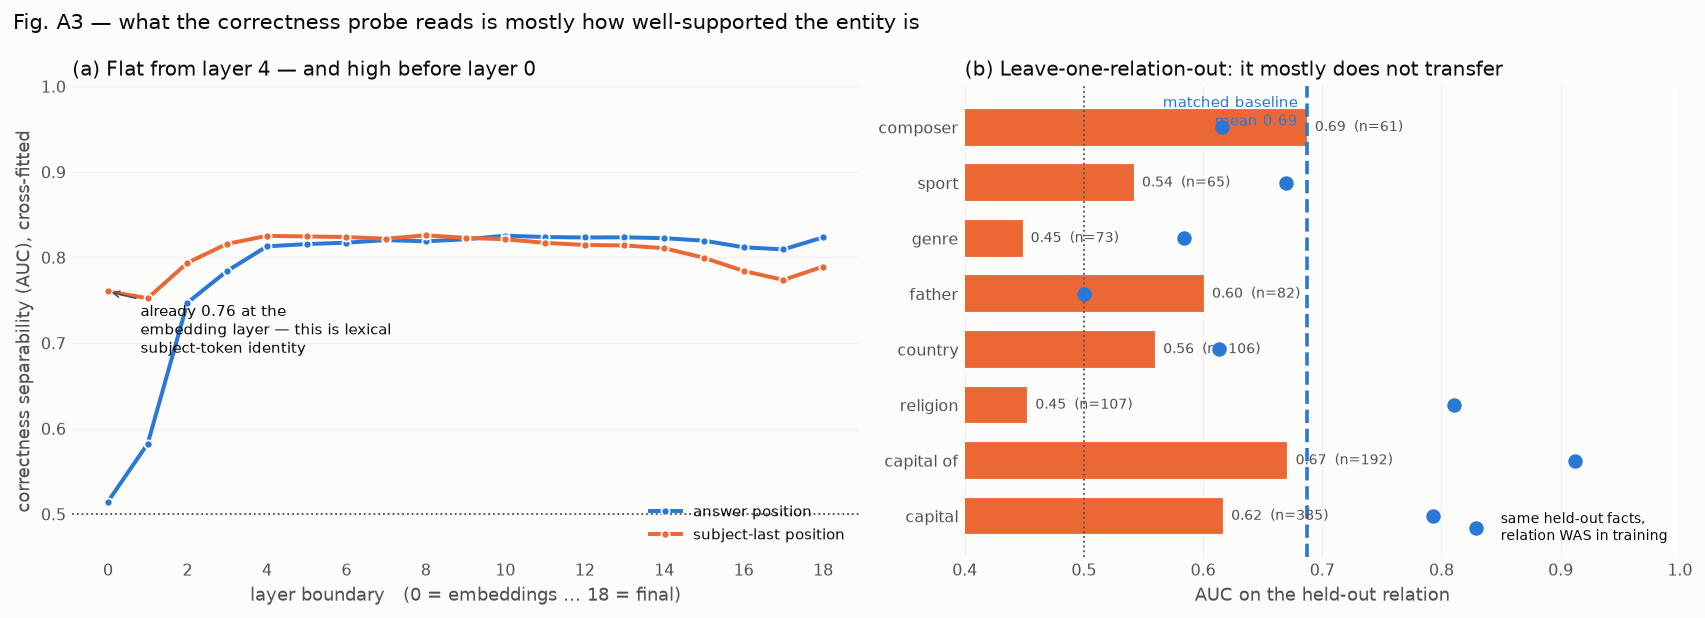

layer            :     0     1     2     3     4     5     6     7     8     9    10    11    12    13    14    15    16    17    18
answer  (x-fit)  :  0.51  0.58  0.75  0.78  0.81  0.82  0.82  0.82  0.82  0.82  0.83  0.82  0.82  0.82  0.82  0.82  0.81  0.81  0.82
subject (x-fit)  :  0.76  0.75  0.79  0.82  0.83  0.82  0.82  0.82  0.83  0.82  0.82  0.82  0.81  0.81  0.81  0.80  0.78  0.77  0.79

checkpoint transfer: mean diagonal 0.896 vs mean off-diagonal 0.740
leave-one-relation-out mean AUC: 0.573 (range 0.45–0.69)
matched baseline (same facts, relation SEEN in training, fact-held-out): 0.687
relation                    n     LORO     seen     cost
capital                   385    0.618    0.793   -0.176
capital of                192    0.672    0.912   -0.241
religion                  107    0.453    0.810   -0.357
country                   106    0.561    0.614   -0.053
father                     82    0.602    0.500   +0.101
genre                      73    0.449    0.584   -0.1

In [67]:
# ── Fig. A3 — cross-fitted separability, and leave-one-relation-out transfer  (hidden §9, §10) ──
HELD = FOLD == 0
probes = []
for i in range(n_t):
    tr = scoreable & ~HELD
    clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, C=0.05))
    clf.fit(Hf_ans[i][tr], h_correct[tr, i])
    probes.append(clf)
te = scoreable & HELD
TRANS = np.full((n_t, n_t), np.nan)
for i in range(n_t):
    for j in range(n_t):
        if 0 < h_correct[te, j].mean() < 1:
            TRANS[i, j] = roc_auc_score(h_correct[te, j], probes[i].predict_proba(Hf_ans[j][te])[:, 1])

# Apples-to-apples relation transfer.  The earlier comparison put the LORO bars next to the mean
# diagonal of TRANS -- a GLOBAL AUC over one held-out fact fold across ALL relations, which scores
# partly on between-relation differences, the very thing LORO removes.  Both arms below are
# evaluated on exactly the same rows (every scoreable fact of the relation); the only difference
# is whether that relation was in the training set.  The "seen" arm is fact-held-out OOF within
# the relation, so neither arm ever scores a fact it trained on.
rel_counts = pd.Series(h_prop[scoreable]).value_counts()
loro, seen = [], []
for r in rel_counts.index[:8]:
    te_r = scoreable & (h_prop == r)
    out_r = scoreable & (h_prop != r)          # relation absent from training entirely
    a_out, a_in = [], []
    for i in range(n_t):
        if not (0 < h_correct[te_r, i].mean() < 1):
            continue
        c = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, C=0.05))
        c.fit(Hf_ans[i][out_r], h_correct[out_r, i])
        a_out.append(roc_auc_score(h_correct[te_r, i], c.predict_proba(Hf_ans[i][te_r])[:, 1]))
        oof = np.full(n_f, np.nan)             # relation present, but never its own scored facts
        for f in range(5):
            tr_in, te_in = scoreable & (FOLD != f), te_r & (FOLD == f)
            if not te_in.any():
                continue
            c2 = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, C=0.05))
            c2.fit(Hf_ans[i][tr_in], h_correct[tr_in, i])
            oof[te_in] = c2.predict_proba(Hf_ans[i][te_in])[:, 1]
        m = te_r & np.isfinite(oof)
        if m.any() and 0 < h_correct[m, i].mean() < 1:
            a_in.append(roc_auc_score(h_correct[m, i], oof[m]))
    if a_out and a_in:
        loro.append((r, int(te_r.sum()), float(np.mean(a_out))))
        seen.append(float(np.mean(a_in)))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.2, 4.8), gridspec_kw={"width_ratios": [1.1, 1]})
ax1.plot(range(19), np.nanmean(sep_xf_ans, 0), color=BLUE, lw=2.2, marker="o", ms=4.5,
         mec=SURF, mew=1, label="answer position")
ax1.plot(range(19), np.nanmean(sep_xf_subj, 0), color=ORANGE, lw=2.2, marker="o", ms=4.5,
         mec=SURF, mew=1, label="subject-last position")
ax1.axhline(0.5, color=INK2, lw=1, ls=":")
ax1.annotate(f"already {np.nanmean(sep_xf_subj, 0)[0]:.2f} at the\nembedding layer — this is "
             "lexical\nsubject-token identity",
             (0, np.nanmean(sep_xf_subj, 0)[0]), xytext=(18, -34), textcoords="offset points",
             fontsize=8.5, color=INK, arrowprops=dict(arrowstyle="->", color=INK2, lw=.9))
ax1.set_xticks(range(0, 19, 2))
ax1.set_ylim(0.45, 1.0)
ax1.set_xlabel("layer boundary   (0 = embeddings … 18 = final)")
ax1.set_ylabel("correctness separability (AUC), cross-fitted")
ax1.set_title("(a) Flat from layer 4 — and high before layer 0", loc="left")
ax1.legend(loc="lower right", fontsize=8.5)

yb = np.arange(len(loro))
ax2.barh(yb, [v for _, _, v in loro], color=ORANGE, edgecolor=SURF, linewidth=1.2, height=.7)
diag = np.nanmean(np.diag(TRANS))          # kept for the checkpoint-transfer printout only
seen_mean = float(np.mean(seen))            # matched baseline: same facts, relation seen
ax2.plot(seen, yb, "o", color=BLUE, ms=7, zorder=4,
         label="same held-out facts,\nrelation WAS in training")
ax2.axvline(seen_mean, color=BLUE, lw=2, ls="--")
ax2.text(seen_mean - .008, len(loro) - .4, f"matched baseline\nmean {seen_mean:.2f}",
         ha="right", va="top", fontsize=8.5, color=BLUE)
ax2.legend(loc="lower right", fontsize=7.5)
ax2.axvline(0.5, color=INK2, ls=":", lw=1)
for i, (_, n_, v) in enumerate(loro):
    ax2.text(v + .006, i, f"{v:.2f}  (n={n_})", va="center", fontsize=8, color=INK2)
ax2.set_yticks(yb, [r for r, _, _ in loro], fontsize=9)
ax2.set_xlim(0.4, 1.0)
ax2.set_xlabel("AUC on the held-out relation")
ax2.set_title("(b) Leave-one-relation-out: it mostly does not transfer", loc="left")

clean(ax1); clean(ax2, axis="x")
fig.suptitle("Fig. A3 — what the correctness probe reads is mostly how well-supported the "
             "entity is", x=0.01, ha="left", fontsize=11.5)
fig.tight_layout(); plt.show()

print("layer            :", " ".join(f"{i:5d}" for i in range(19)))
print("answer  (x-fit)  :", " ".join(f"{v:5.2f}" for v in np.nanmean(sep_xf_ans, 0)))
print("subject (x-fit)  :", " ".join(f"{v:5.2f}" for v in np.nanmean(sep_xf_subj, 0)))
off = TRANS[~np.eye(n_t, dtype=bool)]
print(f"\ncheckpoint transfer: mean diagonal {diag:.3f} vs mean off-diagonal {np.nanmean(off):.3f}")
print(f"leave-one-relation-out mean AUC: {np.mean([v for _, _, v in loro]):.3f} "
      f"(range {min(v for _, _, v in loro):.2f}–{max(v for _, _, v in loro):.2f})")
print(f"matched baseline (same facts, relation SEEN in training, fact-held-out): {seen_mean:.3f}")
print(f"{'relation':22s} {'n':>6s} {'LORO':>8s} {'seen':>8s} {'cost':>8s}")
for (r, n_, v), w in zip(loro, seen):
    print(f"{str(r):22s} {n_:6d} {v:8.3f} {w:8.3f} {v - w:+8.3f}")
print(f"  -> cost of removing the relation from training: "
      f"{np.mean([v for _, _, v in loro]) - seen_mean:+.3f}")
print(f"  (the earlier comparison used the TRANS diagonal, {diag:.3f}, a GLOBAL AUC across all "
      f"relations, which is inflated by between-relation differences)")

**Result.** The subject position is separable at **AUC ≈ 0.76 in the embedding layer**, before
any block has run, and held-out-relation transfer averages ≈**0.573** against ≈**0.687** for a
probe that has seen the relation but is scored on exactly the same facts, fact-held-out — with the
weakest relations at or below chance. (An earlier draft compared 0.573 against **0.896**, but that
0.896 was a global AUC pooled across all relations and was inflated by between-relation
differences. The matched cost of removing a relation is **−0.114**, a third of the apparent gap;
and for two of the eight relations — `father` and `composer`, the two smallest — LORO actually
*beats* the matched baseline, which at n≈60–80 is noise, not transfer.) So most of the
apparent "correctness is linearly legible in the residual stream" is the probe learning **which
relations and entities tend to be answered correctly**, which is exactly the confound Hewitt &
Liang designed control tasks for and which Mallen et al. would predict from entity popularity.

The honest restatement: *the residual stream linearly encodes how well-supported this
entity/relation is, which strongly predicts recall. There is a residual, relation-specific "do I
know this particular fact" component, but it is much smaller than the pooled AUC of ≈0.90
suggests.*

Two consequences to carry into the text. It is why Figure 3 must be read as a paired
difference: lexical/relation identity does not change between adjacent checkpoints, so it
cancels in the DiD but contaminates any single-checkpoint probe level. And the natural repair — recomputing the knowledge direction *within* each relation
— needs no new data, only the existing hidden states.

---
## Figure A4 — neuron-mates share a fate; nothing takes turns

**Source:** `forgetting_internal_features.ipynb` §20 (with the §21 k-sensitivity summarised in
the text).
**Papers:** McCloskey & Cohen (1989), *Catastrophic Interference*; French (1999); Elhage et al.
(2022), *Toy Models of Superposition*; Kotha et al. (2024).

**Why the appendix.** The frequency notebook ends on one loose thread: of every frequency-like
variable, **only competition** — the number of other facts sharing a subject's competitive word
— *raises* the forgetting hazard. The obvious mechanism is the classical one. French (1999)
states it as sharply as it can be stated: catastrophic interference is caused by
**representational overlap**. Translated here: two facts on the same mid-stack neurons should
take turns — one right when the other is wrong.

The neuron dump tests it directly, twice.

**(a) Do neuron-mates' trajectories anti-correlate?** Correlate two facts' correctness
trajectories after removing each fact's own mean (how often it is right) and each checkpoint's
mean (the global accuracy curve), and plot against their shared-neuron count. Competition
predicts the curve goes **down**, below zero. Because relations learn as blocks and relations
share neurons, a second version also removes each relation's own trajectory.

**(b) What do a fact's neuron-mates do at the exact moment it flips?** For every event, take the
fact's 20 *most*-overlapping partners **from other relations** and its 20 *least*-overlapping
ones. Near and far are compared inside the same event, at the same checkpoint, across the same
relation boundary — the only thing that differs is the overlap. Competition predicts the near
group *learns* while the fact is lost; interference predicts the near group is *also* lost.
These are different cells of the 2 × 2 and cannot both be true.

overlap matrices in 9s


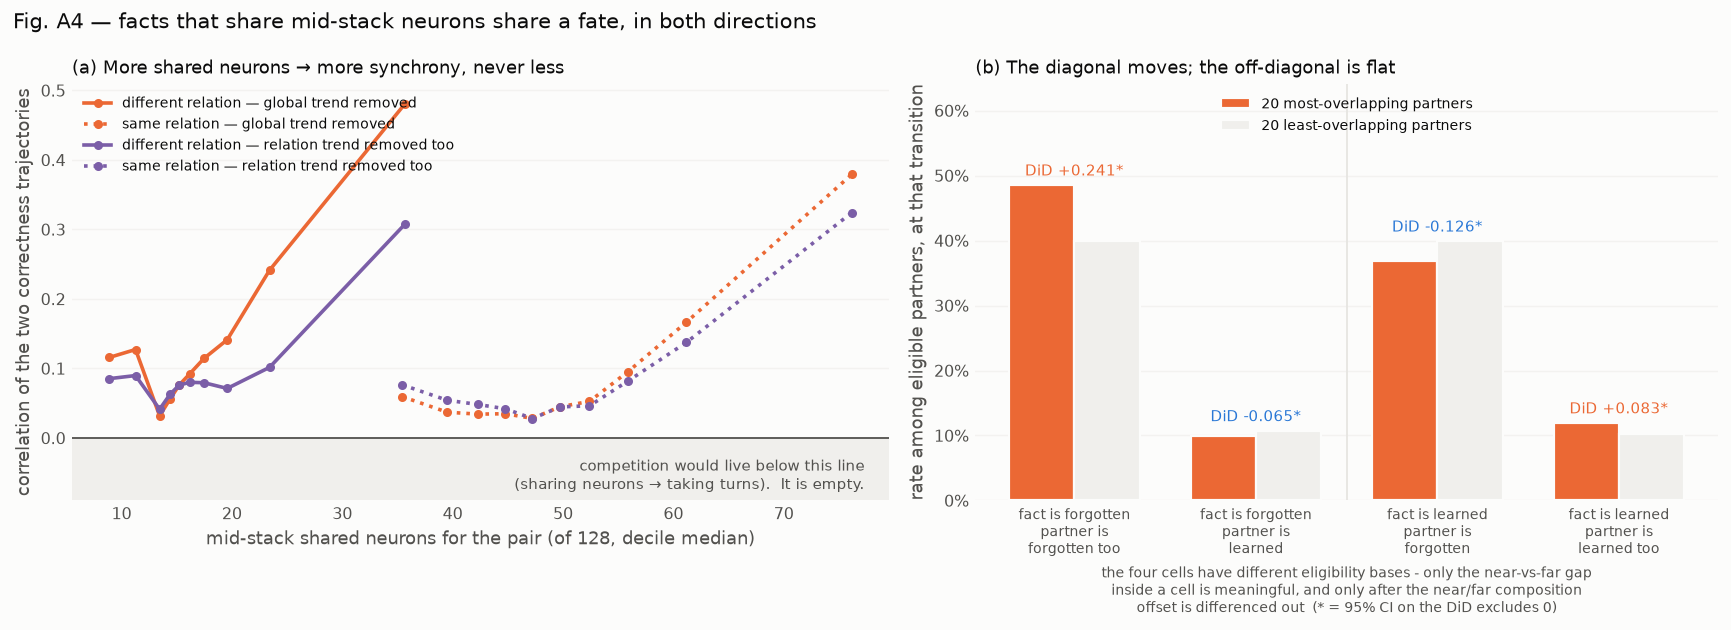

rho(shared neurons, co-fluctuation), global trend removed:
    same relation        +0.1354
    different relation   +0.1487
rho(shared neurons, co-fluctuation), relation trend removed too:
    same relation        +0.0840
    different relation   +0.0969

mid-stack shared neurons out of 128: same relation 50.8  different relation 18.1  (2.81x)

nearest vs farthest cross-relation partners (overlap 37.5 vs 9.5 shared neurons):
  fact forgotten -> partner is forgotten too near 0.485 far 0.399  raw +0.086   DiD +0.241 [+0.195, +0.287]  *
  fact forgotten -> partner is learned     near 0.099 far 0.107  raw -0.008   DiD -0.065 [-0.079, -0.051]  *
  fact learned   -> partner is forgotten   near 0.368 far 0.399  raw -0.031   DiD -0.126 [-0.168, -0.081]  *
  fact learned   -> partner is learned too near 0.119 far 0.102  raw +0.017   DiD +0.083 [+0.072, +0.093]  *

robustness -- the same DiD with neighbours from checkpoint t ALONE, not cumulative:
  fact forgotten -> partner is forgotten too Di

In [68]:
# ── Fig. A4 — do neuron-sharing facts compete, or move together?  (internal §20) ──────
import scipy.sparse as sp

# Mid-stack fact x fact overlap.  One sparse incidence matrix B[fact, neuron] per
# (checkpoint, layer); B @ B.T gives every pair's shared-neuron count in one product, which is
# far cheaper than 858 000 pairwise set intersections.
_t0 = time.time()
# Cumulative overlap: OV_T[t] uses only checkpoints 0..t.  Panel (b) asks who a fact's closest
# neuron-mates were AT the transition, so averaging over all 13 checkpoints -- including ones
# after the event -- would let future information choose the neighbours.  OV (the full average)
# is kept for panel (a), which is a symmetric trajectory correlation with no time direction.
_rows = np.repeat(np.arange(len(ids)), K_NEU)
MID_L = list(range(MID.start, MID.stop))
_run = np.zeros((len(ids), len(ids)), np.float32)
OV_T = []
for si, s_ in enumerate(steps):
    I = _load(s_, "answer", "idx").astype(np.int32)
    for l in MID_L:
        B = sp.csr_matrix((np.ones(_rows.size, np.float32), (_rows, I[:, l, :].ravel())),
                          shape=(len(ids), N_INTER))
        B.data[:] = 1.0                        # force binary before the product
        _run += (B @ B.T).toarray()
    OV_T.append(_run / ((si + 1) * len(MID_L)))
OV = OV_T[-1].copy()
for M in OV_T:
    np.fill_diagonal(M, np.nan)
np.fill_diagonal(OV, np.nan)                   # a fact always shares 128 with itself
print(f"overlap matrices in {time.time() - _t0:.0f}s")

same_prop = prop[:, None] == prop[None, :]
_iu = np.triu_indices(len(ids), 1)
ov_pair, pair_same_prop = OV[_iu], same_prop[_iu]

def cofluctuation(demean_relation):
    """Pearson correlation of two facts' correctness trajectories after removing the per-fact
    mean (how often it is right) and the per-checkpoint mean (the global accuracy curve).  With
    `demean_relation`, each relation's own trajectory goes too, so a relation learning as a
    block cannot manufacture the effect."""
    X = correct.astype(np.float32).copy()
    if demean_relation:
        for p in np.unique(prop):
            m = prop == p
            X[m] -= X[m].mean(0, keepdims=True)
    X = X - X.mean(1, keepdims=True) - X.mean(0, keepdims=True) + X.mean()
    sd = X.std(1); a = sd > 1e-6
    Z = np.zeros_like(X); Z[a] = X[a] / sd[a][:, None]
    return ((Z @ Z.T) / n_steps)[_iu], (a[:, None] & a[None, :])[_iu]

cof_glob, pair_ok = cofluctuation(False)
cof_rel, _ = cofluctuation(True)

NBR_M = 20
# One neighbour set per checkpoint, built only from data available through that checkpoint.
NB_T = []
for t in range(n_steps):
    _Ox = np.where(same_prop | np.isnan(OV_T[t]), np.nan, OV_T[t])   # cross-relation partners only
    NB_T.append((np.argsort(np.nan_to_num(_Ox, nan=-1), 1)[:, ::-1][:, :NBR_M],
                 np.argsort(np.nan_to_num(_Ox, nan=1e9), 1)[:, :NBR_M]))
nbr_near = [x[0] for x in NB_T]
nbr_far = [x[1] for x in NB_T]
_Ox = np.where(same_prop | np.isnan(OV), np.nan, OV)                 # full-average, for reporting
ev_learn = (~correct[:, :-1]) & correct[:, 1:]
ev_forget = correct[:, :-1] & (~correct[:, 1:])

def neighbour_pair_rates(event, outcome, NB, want=True):
    """Paired near/far partner rates at the transitions where the focal fact did (want=True) or
    did not (want=False) have `event`, using neighbours defined from data through t only.
    Returns the focal fact id too, so the bootstrap can cluster on it."""
    near, far, foc = [], [], []
    for t in range(n_steps - 1):
        elig = correct[:, t] if outcome is ev_forget else ~correct[:, t]
        f_elig = correct[:, t] if event is ev_forget else ~correct[:, t]
        for f in np.where(f_elig & (event[:, t] if want else ~event[:, t]))[0]:
            gn, gf = NB[t][0][f], NB[t][1][f]
            gn, gf = gn[elig[gn]], gf[elig[gf]]
            if len(gn) and len(gf):
                near.append(outcome[gn, t].mean()); far.append(outcome[gf, t].mean()); foc.append(f)
    return np.asarray(near), np.asarray(far), np.asarray(foc)

def _cluster(vals, foc, rng, uf, pos):
    sel = np.concatenate([pos[f] for f in rng.choice(uf, uf.size, replace=True)])
    return vals[sel].mean()

def near_far_did(event, outcome, NB, n_boot=1000, seed=0):
    """The estimator this panel needs: a DIFFERENCE-IN-DIFFERENCES.

    The raw near-minus-far gap is confounded, because the near and far groups are not exchangeable
    -- least-overlapping partners have a systematically different baseline propensity to change
    state at all, in EVERY direction.  Subtracting the same near-minus-far gap measured at the
    same checkpoints among focal facts that did NOT have the event cancels that standing offset
    and leaves only what the focal fact's own event adds.  Bootstrap clusters on the focal fact.
    """
    nE, fE, foE = neighbour_pair_rates(event, outcome, NB, want=True)
    nN, fN, foN = neighbour_pair_rates(event, outcome, NB, want=False)
    dE, dN = nE - fE, nN - fN
    rng = np.random.default_rng(seed)
    uf = np.union1d(foE, foN)
    pE = {f: np.where(foE == f)[0] for f in uf}
    pN = {f: np.where(foN == f)[0] for f in uf}
    bt = []
    for _ in range(n_boot):
        pick = rng.choice(uf, uf.size, replace=True)
        iE = np.concatenate([pE[f] for f in pick]); iN = np.concatenate([pN[f] for f in pick])
        if iE.size and iN.size:
            bt.append(dE[iE].mean() - dN[iN].mean())
    return dE.mean(), dN.mean(), dE.mean() - dN.mean(), *np.percentile(bt, [2.5, 97.5]), nE, fE

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.4, 4.9), gridspec_kw={"width_ratios": [1.1, 1]})
for cof, col, lab in ((cof_glob, ORANGE, "global trend removed"),
                      (cof_rel, PURPLE, "relation trend removed too")):
    for m, ls, tag in ((pair_ok & ~pair_same_prop, "-", "different relation"),
                       (pair_ok & pair_same_prop, ":", "same relation")):
        q = pd.qcut(ov_pair[m], 10, labels=False, duplicates="drop")
        x = [np.median(ov_pair[m][q == i]) for i in range(q.max() + 1)]
        y = [cof[m][q == i].mean() for i in range(q.max() + 1)]
        ax1.plot(x, y, color=col, lw=2, ls=ls, marker="o", ms=4, label=f"{tag} — {lab}")
ax1.axhspan(-.09, 0, color=NEUTRAL, zorder=0)
ax1.axhline(0, color=INK2, lw=1)
ax1.set_ylim(-.09, None)
ax1.annotate("competition would live below this line\n(sharing neurons → taking turns).  It is empty.",
             (0.97, 0.015), xycoords="axes fraction", fontsize=8.5, color=INK2, va="bottom", ha="right")
ax1.set_xlabel(f"mid-stack shared neurons for the pair (of {K_NEU}, decile median)")
ax1.set_ylabel("correlation of the two correctness trajectories")
ax1.set_title("(a) More shared neurons → more synchrony, never less", loc="left", fontsize=10)
ax1.legend(loc="upper left", fontsize=7.5)

CASES = [("forgotten", ev_forget, ev_forget, "partner is\nforgotten too"),
         ("forgotten", ev_forget, ev_learn, "partner is\nlearned"),
         ("learned", ev_learn, ev_forget, "partner is\nforgotten"),
         ("learned", ev_learn, ev_learn, "partner is\nlearned too")]
near_v, far_v, cis, dids = [], [], [], []
for _, ev, out, _lab in CASES:
    mE, mN, did, lo, hi, nE, fE = near_far_did(ev, out, NB_T)
    near_v.append(nE.mean()); far_v.append(fE.mean()); dids.append(did); cis.append((lo, hi))
xg = np.arange(4); w = .36
ax2.bar(xg - w/2, near_v, w, color=ORANGE, edgecolor=SURF, linewidth=1.2,
        label=f"{NBR_M} most-overlapping partners")
ax2.bar(xg + w/2, far_v, w, color=NEUTRAL, edgecolor=SURF, linewidth=1.2,
        label=f"{NBR_M} least-overlapping partners")
for i, (a, b, (lo, hi)) in enumerate(zip(near_v, far_v, cis)):
    sig = "" if lo < 0 < hi else "*"
    ax2.text(i, max(a, b) + .015, f"DiD {dids[i]:+.3f}{sig}", ha="center", fontsize=8.5,
             color=INK2 if not sig else (ORANGE if dids[i] > 0 else BLUE))
ax2.set_xticks(xg, [f"fact is {c[0]}\n{c[3]}" for c in CASES], fontsize=7.5)
ax2.axvline(1.5, color=GRID, lw=1)
ax2.yaxis.set_major_formatter(PCT)
ax2.set_ylabel("rate among eligible partners, at that transition")
# bars show the raw near/far levels; the printed DiD is what the inference rests on
ax2.set_ylim(0, max(near_v + far_v) * 1.32)
ax2.set_title("(b) The diagonal moves; the off-diagonal is flat", loc="left", fontsize=10)
ax2.set_xlabel("the four cells have different eligibility bases - only the near-vs-far gap\n"
               "inside a cell is meaningful, and only after the near/far composition\n"
               "offset is differenced out  (* = 95% CI on the DiD excludes 0)", fontsize=8)
ax2.legend(loc="upper center", fontsize=8)

clean(ax1); clean(ax2)
fig.suptitle("Fig. A4 — facts that share mid-stack neurons share a fate, in both directions",
             x=0.01, ha="left", fontsize=11.5)
fig.tight_layout(); plt.show()

for nm, cof in (("global trend removed", cof_glob), ("relation trend removed too", cof_rel)):
    print(f"rho(shared neurons, co-fluctuation), {nm}:")
    for lab, m in (("same relation", pair_ok & pair_same_prop),
                   ("different relation", pair_ok & ~pair_same_prop)):
        print(f"    {lab:20s} {spearmanr(ov_pair[m], cof[m])[0]:+.4f}")
print(f"\nmid-stack shared neurons out of {K_NEU}: same relation "
      f"{np.nanmean(ov_pair[pair_same_prop]):.1f}  different relation "
      f"{np.nanmean(ov_pair[~pair_same_prop]):.1f}  "
      f"({np.nanmean(ov_pair[pair_same_prop]) / np.nanmean(ov_pair[~pair_same_prop]):.2f}x)")
print(f"\nnearest vs farthest cross-relation partners (overlap "
      f"{np.nanmean(np.take_along_axis(_Ox, nbr_near[-1], 1)):.1f} vs "
      f"{np.nanmean(np.take_along_axis(_Ox, nbr_far[-1], 1)):.1f} shared neurons):")
for (evn, _, _, out_lab), a, b, d, (lo, hi) in zip(CASES, near_v, far_v, dids, cis):
    print(f"  fact {evn:9s} -> {out_lab.replace(chr(10), ' '):22s} "
          f"near {a:.3f} far {b:.3f}  raw {a - b:+.3f}   DiD {d:+.3f} [{lo:+.3f}, {hi:+.3f}]"
          f"{'  *' if lo * hi > 0 else '   (null)'}")
print("\nrobustness -- the same DiD with neighbours from checkpoint t ALONE, not cumulative:")
NB_AT = []
for t in range(n_steps):
    _O = OV_T[t] * (t + 1) - (OV_T[t - 1] * t if t else 0)          # back out the single-step overlap
    _Ox = np.where(same_prop | np.isnan(_O), np.nan, _O)
    NB_AT.append((np.argsort(np.nan_to_num(_Ox, nan=-1), 1)[:, ::-1][:, :NBR_M],
                  np.argsort(np.nan_to_num(_Ox, nan=1e9), 1)[:, :NBR_M]))
for (evn, ev, out, out_lab) in CASES:
    _, _, d, lo, hi, _, _ = near_far_did(ev, out, NB_AT)
    print(f"  fact {evn:9s} -> {out_lab.replace(chr(10), ' '):22s} DiD {d:+.3f} "
          f"[{lo:+.3f}, {hi:+.3f}]{'  *' if lo * hi > 0 else '   (null)'}")

**Result — there is no competition anywhere in this data, and the corrected test says so far more
sharply than the original did.**

Test (a) points the wrong way for the interference hypothesis. Among cross-relation pairs the
correctness correlation reaches ≈+0.48 in the top overlap decile against ≈+0.12 in the bottom, and
climbs steeply over the top three. It is **not monotonic** — the curve dips to ≈+0.03 in the third
decile and does not clear the bottom decile again until the seventh — so the honest claim is
"strongly increasing at high overlap", not "increasing throughout". Removing each relation's own
trajectory cuts the global correlation by about a third (+0.149 to +0.097 across relations) but
does not touch the sign. What matters for the hypothesis is
unaffected: the region below zero, where every form of interference would have to live, is **empty
at every overlap level**.

Test (b) is the clean one, and it needed an estimator the first version did not use. The raw
near-minus-far gap is **confounded**: the 20 least-overlapping partners are not an exchangeable
control group — they have a systematically lower baseline propensity to change state at all, in
every direction. Differencing against the same near-minus-far gap measured at the same checkpoints
among focal facts that did *not* have the event removes that standing offset. The result is a
fully significant 2 × 2, and all four cells point the same way:

| focal fact | partner outcome | DiD | 95% CI | reading |
|---|---|---|---|---|
| forgotten | forgotten too | **+0.241** | [+0.195, +0.287] | shared fate |
| learned | learned too | **+0.083** | [+0.072, +0.093] | shared fate |
| forgotten | learned | **−0.065** | [−0.079, −0.051] | *anti*-competition |
| learned | forgotten | **−0.126** | [−0.168, −0.081] | *anti*-competition |

Competition requires the two bottom cells to be **positive** — a fact's neuron-mates should gain
when it loses. They are significantly negative. Neuron-mates are not merely un-competitive; they
are *less* likely to move in opposite directions than the baseline pairing predicts. The same
signs and significance hold when the neighbours are defined from a single checkpoint rather than
cumulatively (printed as robustness above), so the conclusion does not depend on that choice.

**What this means.** French's overlap→interference prediction does not transfer to factual recall
in a pretraining LM at this resolution. Overlap here marks facts the model processes with the
*same machinery*, and shared machinery means a shared response to whatever the next 50k steps do
to it. The mid-stack behaves like a shared circuit being retuned, not like a contested resource —
which also re-reads the competition variable from the frequency notebook: a subject whose token is
shared by many facts gets a *less discriminative* representation, so its facts are all weakly
stored, and being weakly stored together they wobble together. That is a failure of the key, not a
battle over the value.

**Robustness worth one sentence in the text.** Re-running the whole test at k ∈ {8, 16, 32, 64,
128} leaves the null intact at every k — including k = 8, where the analysis sees only each fact's
eight most active neurons. There is no contested core hiding under a synchronised tail. The one
limit that remains is temporal, not spatial: interference that resolves inside a single 50k-step
interval is invisible at any k.


---
## Figure A5 — a noise floor: is "forgetting" just correctness resampled at each checkpoint?

**Source:** `forgetting_internal_features.ipynb` §10.
**Papers:** Toneva et al. (2019) (the *unforgettable examples* baseline); Maini et al. (2022),
*Second-Split Forgetting*.

**Why the appendix.** This is the test the entire project most needs, because every fragility
result is vulnerable to one deflationary reading. `correct` is a lenient substring match on a
greedy generation. If correctness were simply a **noisy sample** from the model's answer
distribution, then low-gold-probability facts would flip back and forth *by construction*, and
"forgetting strikes fragile facts" would be a restatement of "a coin weighted 0.1 comes up tails
a lot" — no learning dynamics required.

The null makes that precise. Calibrate P(correct | gold probability) on all (fact, checkpoint)
observations, then **resample every observation independently** from that calibration, keeping
each fact's real gold-probability trajectory. The null has, by construction, the same
relationship between confidence and correctness as the real data — it differs *only* in having
no memory from one checkpoint to the next. Comparing the resulting **dynamics** isolates exactly
what the scalar cannot explain.

It goes in the appendix rather than the body because it establishes that there is something to
explain, not what the explanation is.

gold_prob -> correct:  AUC (ranking only) 0.756   Brier 0.1605 vs 0.1998 for a constant predictor   skill +0.197
10-quantile ECE 0.0418  (mean |predicted - observed| across deciles)
reliability (cross-fitted): 0.07->0.11  0.09->0.11  0.11->0.13  0.15->0.14  0.19->0.19  0.24->0.23  0.31->0.26  0.41->0.32  0.53->0.49  0.66->0.79
  (predicted -> observed per decile; close pairs mean the null inherits a fair confidence-correctness map, which is the only property it needs)


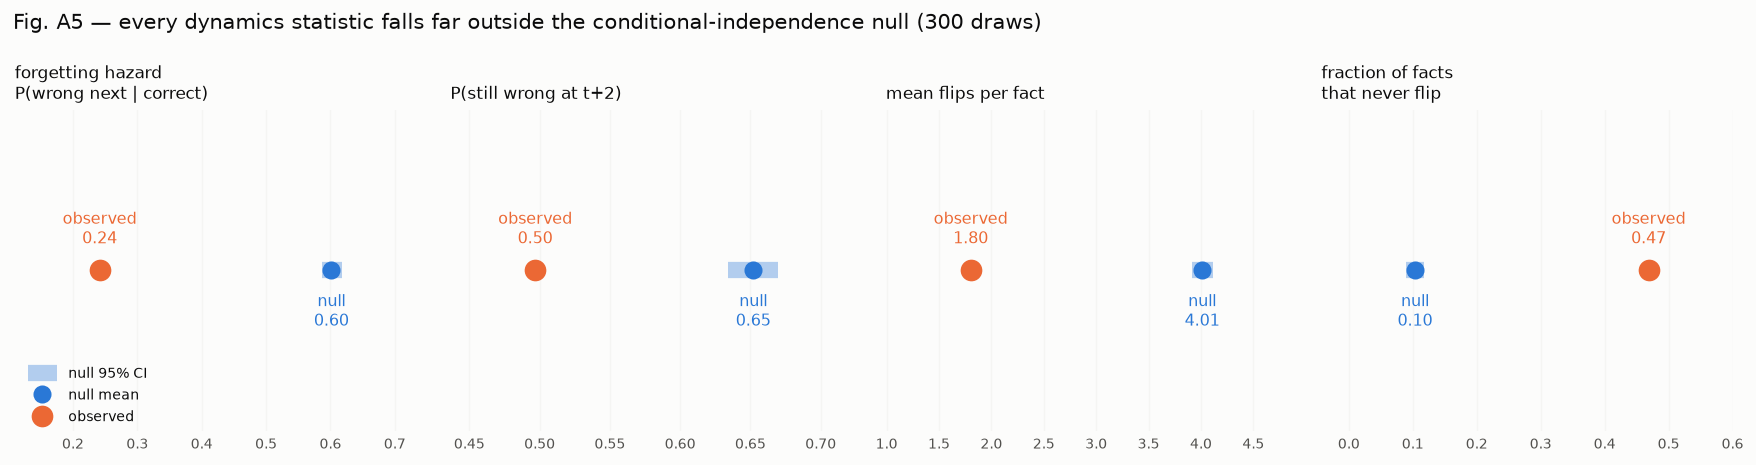


                                observed  null mean          null 95% CI
hazard                             0.241      0.601   [0.586, 0.618]
P(still wrong t+2)                 0.497      0.652   [0.634, 0.669]
mean flips/fact                    1.802      4.012   [3.915, 4.116]
frac never flipping                0.469      0.103   [0.090, 0.117]


In [69]:
# ── Fig. A5 — the conditional-independence null  (internal §10) ───────────────────────
gp_mat = NEWP["gold_prob"]
lp = np.log10(np.clip(gp_mat, 1e-9, 1))
obsm = np.isfinite(lp)
Xc = np.column_stack([lp[obsm], lp[obsm] ** 2])
# Cross-fitted, because the null is generated from this fit and an in-sample fit would give the
# null a small unearned advantage.  AUC is a RANKING measure and says nothing about whether the
# probabilities are right, so the Brier score and a reliability table are what actually license
# "the null reproduces the confidence-correctness relationship".
_y = correct[obsm]
_fold = np.random.default_rng(1).integers(0, 5, size=_y.size)
phat = np.zeros_like(gp_mat)
_p = np.zeros(_y.size)
for f in range(5):
    tr, te = _fold != f, _fold == f
    _p[te] = LogisticRegression(max_iter=1000).fit(Xc[tr], _y[tr]).predict_proba(Xc[te])[:, 1]
phat[obsm] = _p
_brier = np.mean((_p - _y) ** 2)
_base = np.mean((_y.mean() - _y) ** 2)
print(f"gold_prob -> correct:  AUC (ranking only) {roc_auc_score(_y, _p):.3f}   "
      f"Brier {_brier:.4f} vs {_base:.4f} for a constant predictor   "
      f"skill {1 - _brier / _base:+.3f}")
_q = pd.qcut(_p, 10, labels=False, duplicates="drop")
_ece = float(np.mean([abs(_p[_q == b].mean() - _y[_q == b].mean()) * (_q == b).mean()
                      for b in range(_q.max() + 1)]) * (_q.max() + 1))
print(f"10-quantile ECE {_ece:.4f}  (mean |predicted - observed| across deciles)")
print("reliability (cross-fitted): ", end="")
print("  ".join(f"{_p[_q == b].mean():.2f}->{_y[_q == b].mean():.2f}" for b in range(_q.max() + 1)))
print("  (predicted -> observed per decile; close pairs mean the null inherits a fair "
      "confidence-correctness map, which is the only property it needs)")

def dynamics(C):
    """Four summaries of the *temporal* structure of a correctness matrix."""
    haz = (C[:, :-1] & ~C[:, 1:]).sum() / max(C[:, :-1].sum(), 1)
    pers = [~C[C[:, t] & ~C[:, t + 1], t + 2] for t in range(n_steps - 2)
            if (C[:, t] & ~C[:, t + 1]).any()]
    flips = (C[:, 1:] != C[:, :-1]).sum(1)
    return haz, np.mean(np.concatenate(pers)), flips.mean(), (flips == 0).mean()

rng = np.random.default_rng(0)
observed = dynamics(correct)
null = np.array([dynamics(rng.random(gp_mat.shape) < phat) for _ in range(300)])

LABELS = ["forgetting hazard\nP(wrong next | correct)", "P(still wrong at t+2)",
          "mean flips per fact", "fraction of facts\nthat never flip"]
# The null is extremely tight, so a histogram renders as a hairline: show each metric as
# observed vs null-mean dots with the null 95% CI drawn as a bar.
fig, axes = plt.subplots(1, 4, figsize=(13.6, 3.6))
for i, (ax, lab) in enumerate(zip(axes, LABELS)):
    lo_n, hi_n = np.percentile(null[:, i], [2.5, 97.5])
    ax.hlines(0, lo_n, hi_n, color=BLUE, lw=9, alpha=.35, zorder=1, label="null 95% CI")
    ax.plot(null[:, i].mean(), 0, "o", color=BLUE, ms=9, zorder=2, label="null mean")
    ax.plot(observed[i], 0, "o", color=ORANGE, ms=11, zorder=3, label="observed")
    lo_x, hi_x = min(observed[i], lo_n), max(observed[i], hi_n)
    pad = (hi_x - lo_x) * 0.35 + 1e-6
    ax.set_xlim(lo_x - pad, hi_x + pad)
    ax.annotate(f"observed\n{observed[i]:.2f}", (observed[i], 0), color=ORANGE, fontsize=9,
                ha="center", va="bottom", xytext=(0, 12), textcoords="offset points")
    ax.annotate(f"null\n{null[:, i].mean():.2f}", (null[:, i].mean(), 0), color=BLUE, fontsize=9,
                ha="center", va="top", xytext=(0, -12), textcoords="offset points")
    ax.set_ylim(-1, 1); ax.set_yticks([])
    ax.set_title(lab, loc="left", fontsize=9.5)
    ax.tick_params(length=0, labelsize=8); ax.grid(axis="x", alpha=.3)
    for s_ in ax.spines.values():
        s_.set_visible(False)
axes[0].legend(loc="lower left", fontsize=8, bbox_to_anchor=(0, -0.02))
fig.suptitle("Fig. A5 — every dynamics statistic falls far outside the conditional-independence "
             "null (300 draws)", x=0.01, ha="left", fontsize=11.5)
fig.tight_layout(); plt.show()

print(f"\n{'':30s} {'observed':>9s} {'null mean':>10s} {'null 95% CI':>20s}")
for i, lab in enumerate(["hazard", "P(still wrong t+2)", "mean flips/fact", "frac never flipping"]):
    lo_n, hi_n = np.percentile(null[:, i], [2.5, 97.5])
    print(f"{lab:30s} {observed[i]:9.3f} {null[:, i].mean():10.3f}   [{lo_n:.3f}, {hi_n:.3f}]")

**Result — the deflationary reading is decisively rejected, in the direction that strengthens
the thesis.** The null inherits the confidence↔correctness map (cross-fitted Brier 0.161 against
0.200 for a constant predictor, skill +0.197, 10-quantile ECE 0.042; AUC 0.756 — a *ranking* number that says nothing
about calibration on its own) but has no memory across checkpoints, and its dynamics are nothing
like the observed ones. Real correctness is **≈2.2× more persistent** in flips per fact than an
independently resampled read-out of the same gold probabilities, and ≈47% of facts never flip at
all against a null expectation of ≈10% — a direct analogue of Toneva et al.'s *unforgettable
examples*.

*How exact is "inherits"?* Not exact, and the reliability table says where it slips: the quadratic
logistic fit tracks the observed rate closely through the first six deciles (0.07→0.11, 0.19→0.19,
0.24→0.23) but under-predicts at the top (0.66→0.79) and over-predicts around the eighth
(0.41→0.32). The null is therefore an approximation to $P(\text{correct} \mid p_{\text{gold}})$,
not a reproduction of it. The gaps between observed and null here are an order of magnitude larger
than that miscalibration, so the conclusion is safe — but the earlier wording "reproduces the
relationship exactly" was wrong and the figure should not lean on it.

*On the name.* This is a **conditional-independence** null, not a "stochastic read-out" null.
Generation is greedy, so correctness is not literally a Bernoulli draw at each checkpoint; what
the null removes is any dependence between checkpoints beyond what gold probability already
carries. That is the assumption being tested, and it is the one that fails.

Two consequences, and the second is why the body figures exist. (1) "Forgetting strikes fragile
facts" survives — it is not an artefact of stochastic scoring. (2) But the same result says gold
probability is a **badly incomplete** description of a fact's state, which is precisely why the
neuron features in Figure 2 can add to it, and why Figure 1's mid-stack signal exists at all. This
figure is the proof *by elimination* that a fact carries state the output scalar misses; Figure 2
is the positive counterpart that names part of it.


---
# Summary — what the eight figures say together

**Body.**

1. **Where.** Forgetting is a mid-stack failure. Survivors and soon-to-be-forgotten facts are
   not separated in that direction through boundary 7; the gap opens at boundary 8 (248 vs 468 in
   median gold rank), reaches an order of magnitude by boundary 10 (3 vs 27) and holds it to the
   final layer — the shape of an *attribute-extraction*
   failure, which a read-out failure would not produce.
2. **When, and how well can it be seen coming.** The fact's neuron set was already churning
   during the *previous* interval, deepest at a layer inside the band Figure 1 flags, and ten
   summaries of the neuron dump add to what the internal scalar features already say — within
   checkpoints 0.713 together against 0.694 for those features alone, though the neuron block
   alone (0.685) does not beat them.
3. **What kind of event.** Not an erasure. The representation gap is fully open a checkpoint
   *before* the flip (probe 0.44 vs 0.72 for survivors) and the flip itself removes nothing
   measurable (DiD +0.08); 44% of flips sharpen rather than flatten, and half reverse within one
   checkpoint.

**Appendix.** A1 describes the mid-stack band the body figures use — a *privacy* band, not the
sparse-and-volatile one an earlier draft claimed. A2 shows one CV choice turned a 0.70 probe into
a 0.48 one, and re-scores every predictor with both controls (fact-grouped folds, AUC within
checkpoint). A3 shows the correctness direction is largely lexical/relation identity, which
bounds every probe number including Figure 3's. A4 rules out interference between neuron-mates: once the
near/far composition offset is differenced out, all four cells of the 2×2 are significant and the
two competition cells are *negative*. A5 rules out the resampled-correctness account of the
whole phenomenon.

**The through-line.** Forgetting in LMEnt is neither erasure nor a contest. It is a **shared
mid-stack circuit being continuously retuned**, with each fact's survival depending on how
sharply and how privately it happens to be written into that circuit at the moment. A flip is
the visible crossing of a threshold a fact was already sitting on: the representation gap is
open a checkpoint early (Fig. 3), the neurons were already moving (Fig. 2), and the deficit is
localised where the attribute is extracted (Fig. 1). That is why weak storage predicts loss, why
churn adds to it, why neuron-mates rise and fall together — and, with the frequency notebook,
why evidence for a fact is the strongest protection against losing it.

**What is deliberately not here.** The frequency/hazard results (their own notebook), the fact
cartography and per-relation hazard tables (descriptive, superseded), the relation-geography and
k-sensitivity panels (robustness, better as text), and the event-aligned scalar curves
(subsumed by Figure 1).